# PRAICP-1004 — Rainfall Time Series Forecasting

**Author:** Reuben C Mathew

## Business case
Develop a machine learning model that predicts rainfall for the **next one year** from historical data,
and forecasts the **highest rainfall recorded in a single day** for each month.

## Project goals
1. Data understanding and preprocessing.
2. An ML model to forecast both targets.

## Data
Three monthly series recorded at the **Changi Climate Station, Singapore** (source: National Environment Agency,
data.gov.sg), covering **January 1982 to June 2020**:

| File | Column | Unit |
|---|---|---|
| `rainfall-monthly-total.csv` | `total_rainfall` | mm |
| `rainfall-monthly-highest-daily-total.csv` | `maximum_rainfall_in_a_day` | mm |
| `rainfall-monthly-number-of-rain-days.csv` | `no_of_rainy_days` | days (≥ 0.2 mm) |

## Approach
1. **Data understanding**: quality checks, EDA, outliers, hypothesis tests.
2. **Time series analysis**: trend / seasonality / cyclical / random components, stationarity (ADF, KPSS), ACF/PACF.
3. **Evaluation design**: a 12-month-ahead rolling-origin backtest plus an untouched final holdout year.
4. **Models**: naive and climatology baselines → AR, MA, ARIMA, SARIMA (AIC selection), Holt-Winters →
   feature-engineered Linear Regression, Random Forest, XGBoost → LSTM (Keras) → an ensemble of the lightweight models.
5. **Uncertainty**: XGBoost quantile regression for 80% prediction intervals.
6. **Final forecast**: July 2020 – June 2021 for both targets, saved forecasts and model card.

## 1. Setup

In [1]:
import os, warnings, itertools, json
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import statsmodels.api as sm

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

warnings.filterwarnings('ignore')   # after imports: statsmodels re-enables its own warnings on import
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)
SEED = 42
np.random.seed(SEED)

DATA_DIR = 'data'        # folder holding the three CSV files
OUT_DIR = 'outputs'      # saved models and forecasts
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Data loading and quality checks

In [2]:
total = pd.read_csv(f'{DATA_DIR}/rainfall-monthly-total.csv')
maxday = pd.read_csv(f'{DATA_DIR}/rainfall-monthly-highest-daily-total.csv')
raindays = pd.read_csv(f'{DATA_DIR}/rainfall-monthly-number-of-rain-days.csv')

for name, d in [('total', total), ('max daily', maxday), ('rain days', raindays)]:
    print(f'{name:10s} shape={d.shape}  columns={list(d.columns)}')
total.head()

total      shape=(462, 2)  columns=['month', 'total_rainfall']
max daily  shape=(462, 2)  columns=['month', 'maximum_rainfall_in_a_day']
rain days  shape=(462, 2)  columns=['month', 'no_of_rainy_days']


,month,total_rainfall
0,1982-01,107.10
1,1982-02,27.80
2,1982-03,160.80
3,1982-04,157.00
4,1982-05,102.20


In [3]:
df = (total.merge(maxday, on='month', how='outer')
           .merge(raindays, on='month', how='outer'))
df['month'] = pd.to_datetime(df['month'], format='%Y-%m')
df = df.set_index('month').sort_index()

full_range = pd.date_range(df.index.min(), df.index.max(), freq='MS')
print('Period              :', df.index.min().strftime('%Y-%m'), 'to', df.index.max().strftime('%Y-%m'))
print('Rows                :', len(df))
print('Missing months      :', len(full_range.difference(df.index)))
print('Duplicate months    :', df.index.duplicated().sum())
print('Null values         :', df.isna().sum().to_dict())
print('Negative values     :', (df < 0).sum().to_dict())
print('Max-day > total     :', (df['maximum_rainfall_in_a_day'] > df['total_rainfall']).sum())
print('Rain days > 31      :', (df['no_of_rainy_days'] > 31).sum())
df = df.asfreq('MS')
df.info()

Period              : 1982-01 to 2020-06
Rows                : 462
Missing months      : 0
Duplicate months    : 0
Null values         : {'total_rainfall': 0, 'maximum_rainfall_in_a_day': 0, 'no_of_rainy_days': 0}
Negative values     : {'total_rainfall': 0, 'maximum_rainfall_in_a_day': 0, 'no_of_rainy_days': 0}
Max-day > total     : 0
Rain days > 31      : 0
<class 'pandas.DataFrame'>
DatetimeIndex: 462 entries, 1982-01-01 to 2020-06-01
Freq: MS
Data columns (total 3 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   total_rainfall             462 non-null    float64
 1   maximum_rainfall_in_a_day  462 non-null    float64
 2   no_of_rainy_days           462 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 14.4 KB


The data is clean: 462 consecutive months, no gaps, nulls, duplicates or impossible values
(the highest single-day rainfall never exceeds the monthly total). No imputation is needed.

**Note:** 2020 contains only January–June, so it is excluded from any yearly aggregation.

In [4]:
TARGET_TOTAL = 'total_rainfall'
TARGET_MAX = 'maximum_rainfall_in_a_day'
df['year'] = df.index.year
df['month_num'] = df.index.month
df['month_name'] = df.index.strftime('%b')
MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
df[[TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days']].describe().T

,count,mean,std,min,25%,50%,75%,max
total_rainfall,462.00,176.24,113.30,0.20,89.03,158.45,237.95,765.90
maximum_rainfall_in_a_day,462.00,52.36,35.69,0.20,30.62,43.45,63.15,216.20
no_of_rainy_days,462.00,13.96,4.95,1.00,11.00,14.00,18.00,27.00


## 3. Exploratory data analysis

### 3.1 The three series over time

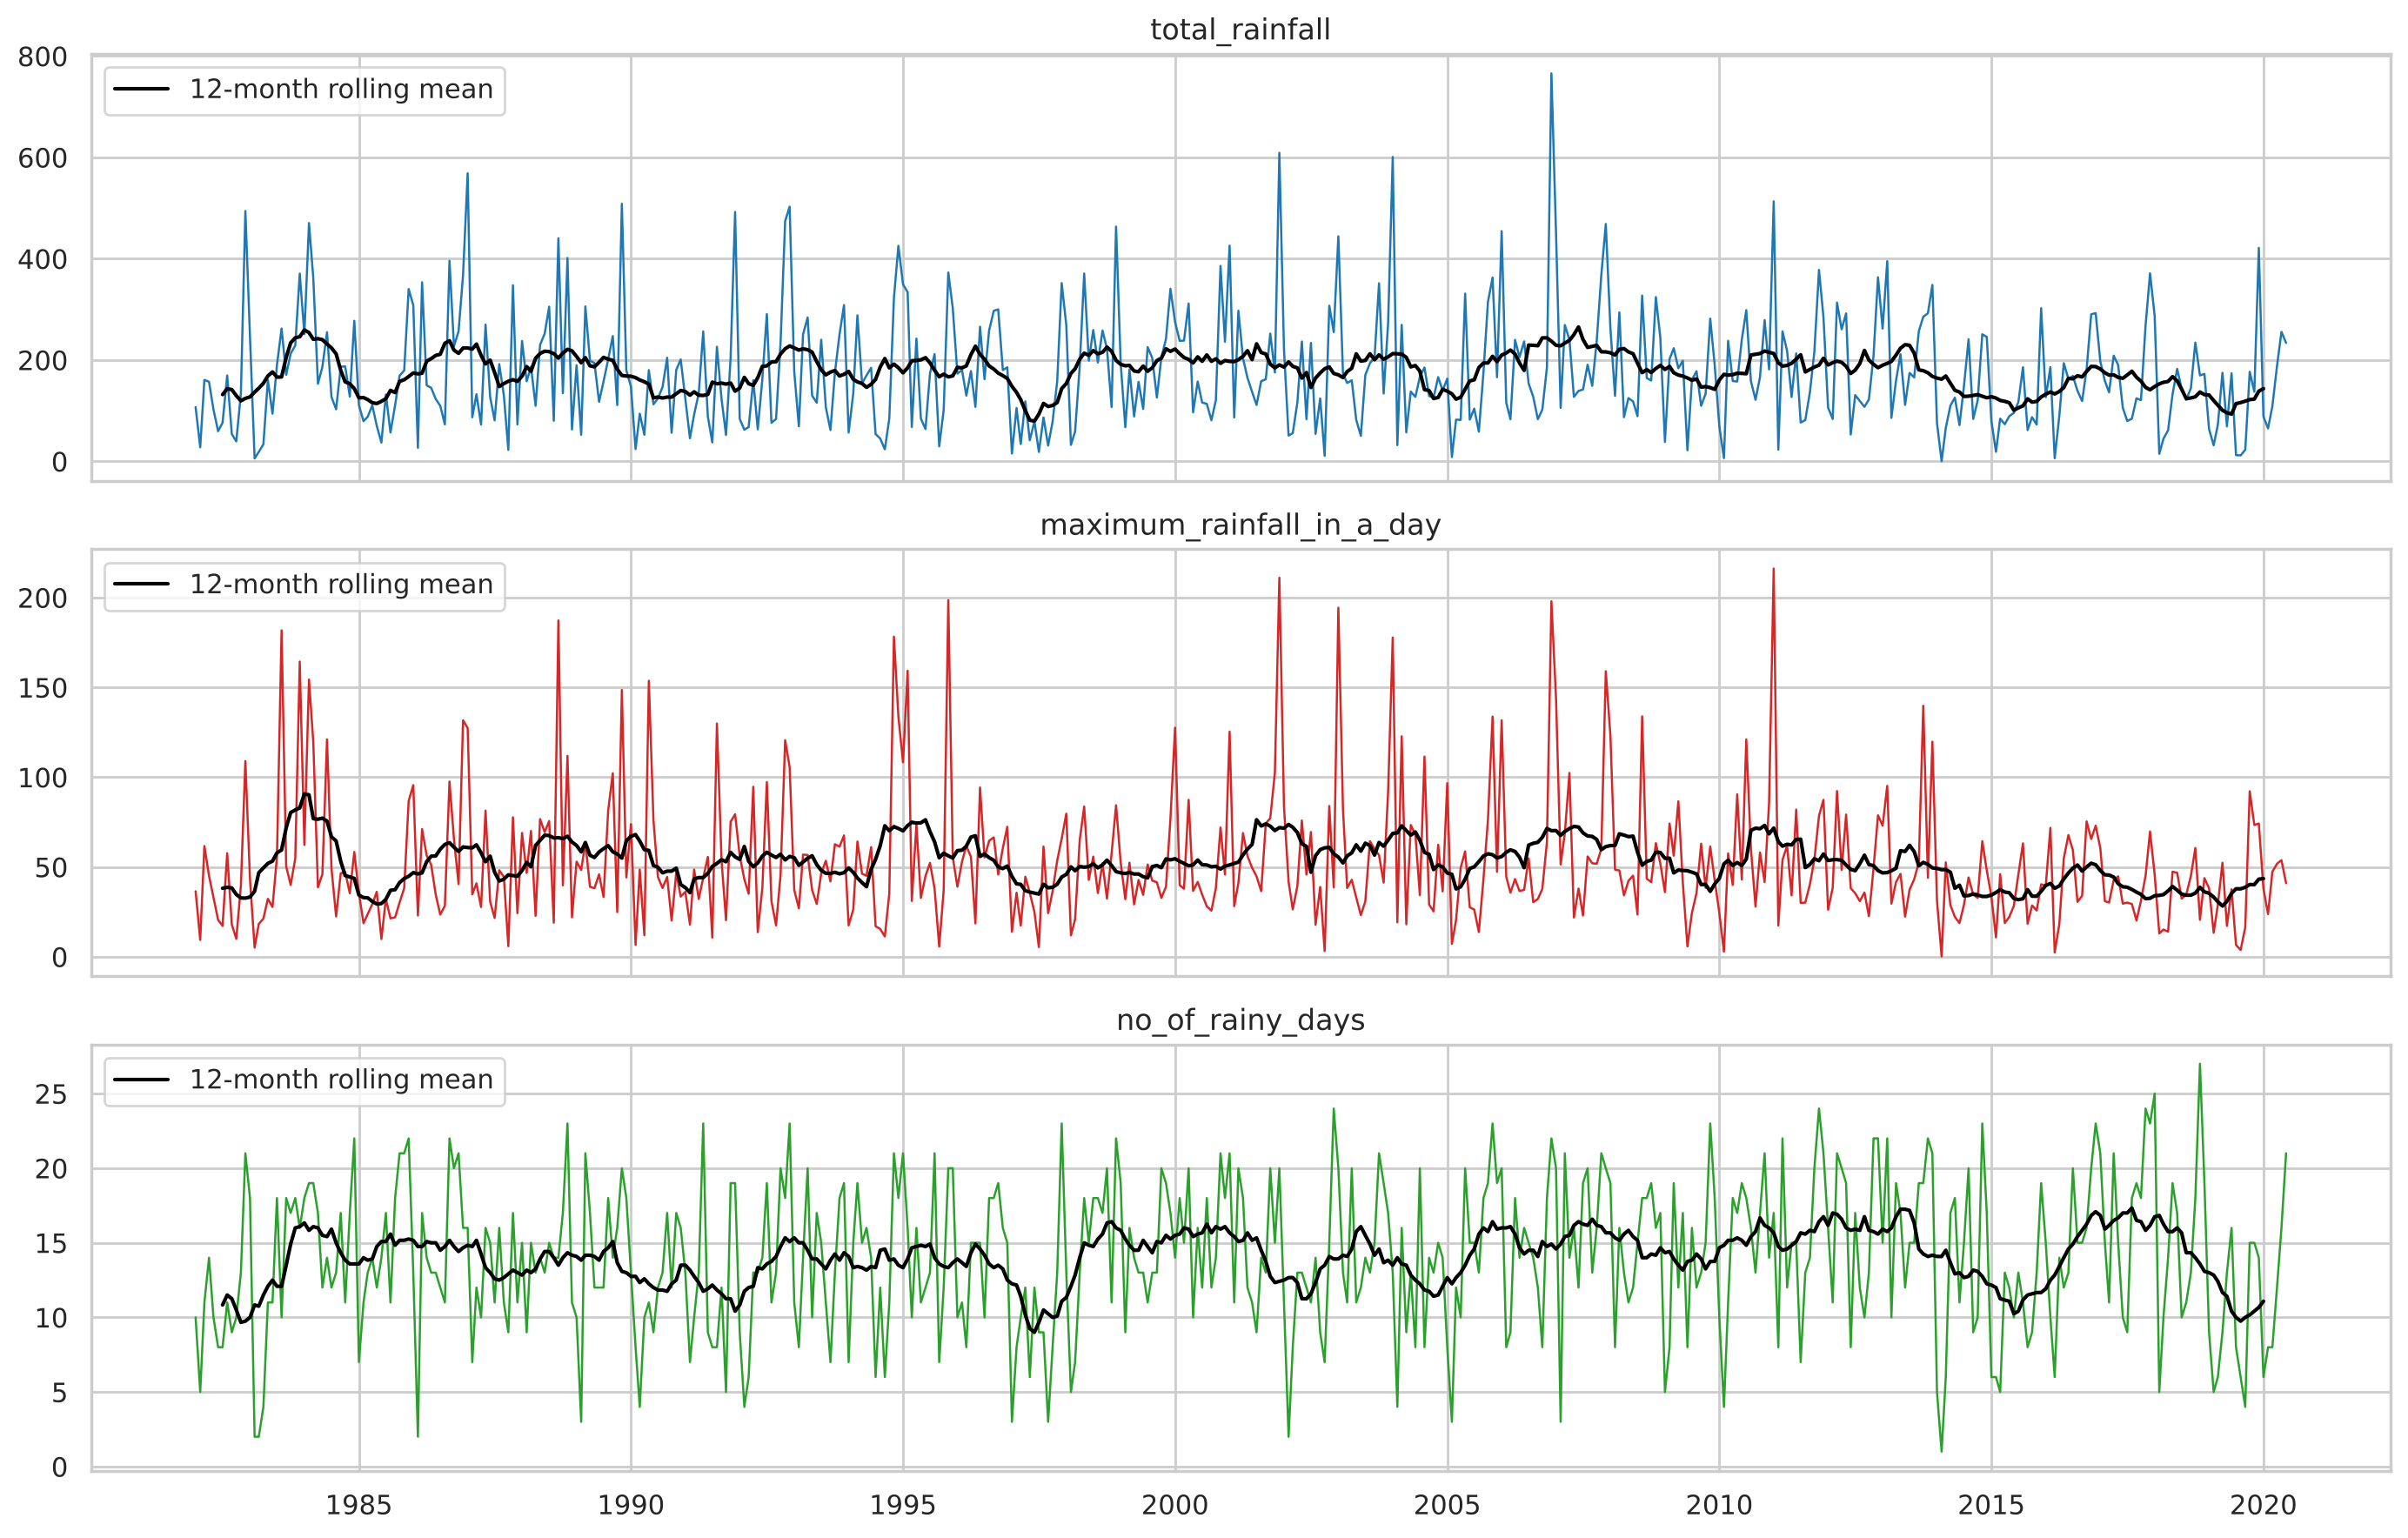

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, col, color in zip(axes, [TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days'], ['tab:blue', 'tab:red', 'tab:green']):
    ax.plot(df.index, df[col], color=color, lw=0.9)
    ax.plot(df.index, df[col].rolling(12, center=True).mean(), color='black', lw=1.5, label='12-month rolling mean')
    ax.set_title(col); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

The series fluctuate strongly from month to month around a fairly flat 12-month rolling mean.
There is no obvious long-term trend; the dominant visible structure is seasonal plus large random variation.

### 3.2 Distributions and skewness

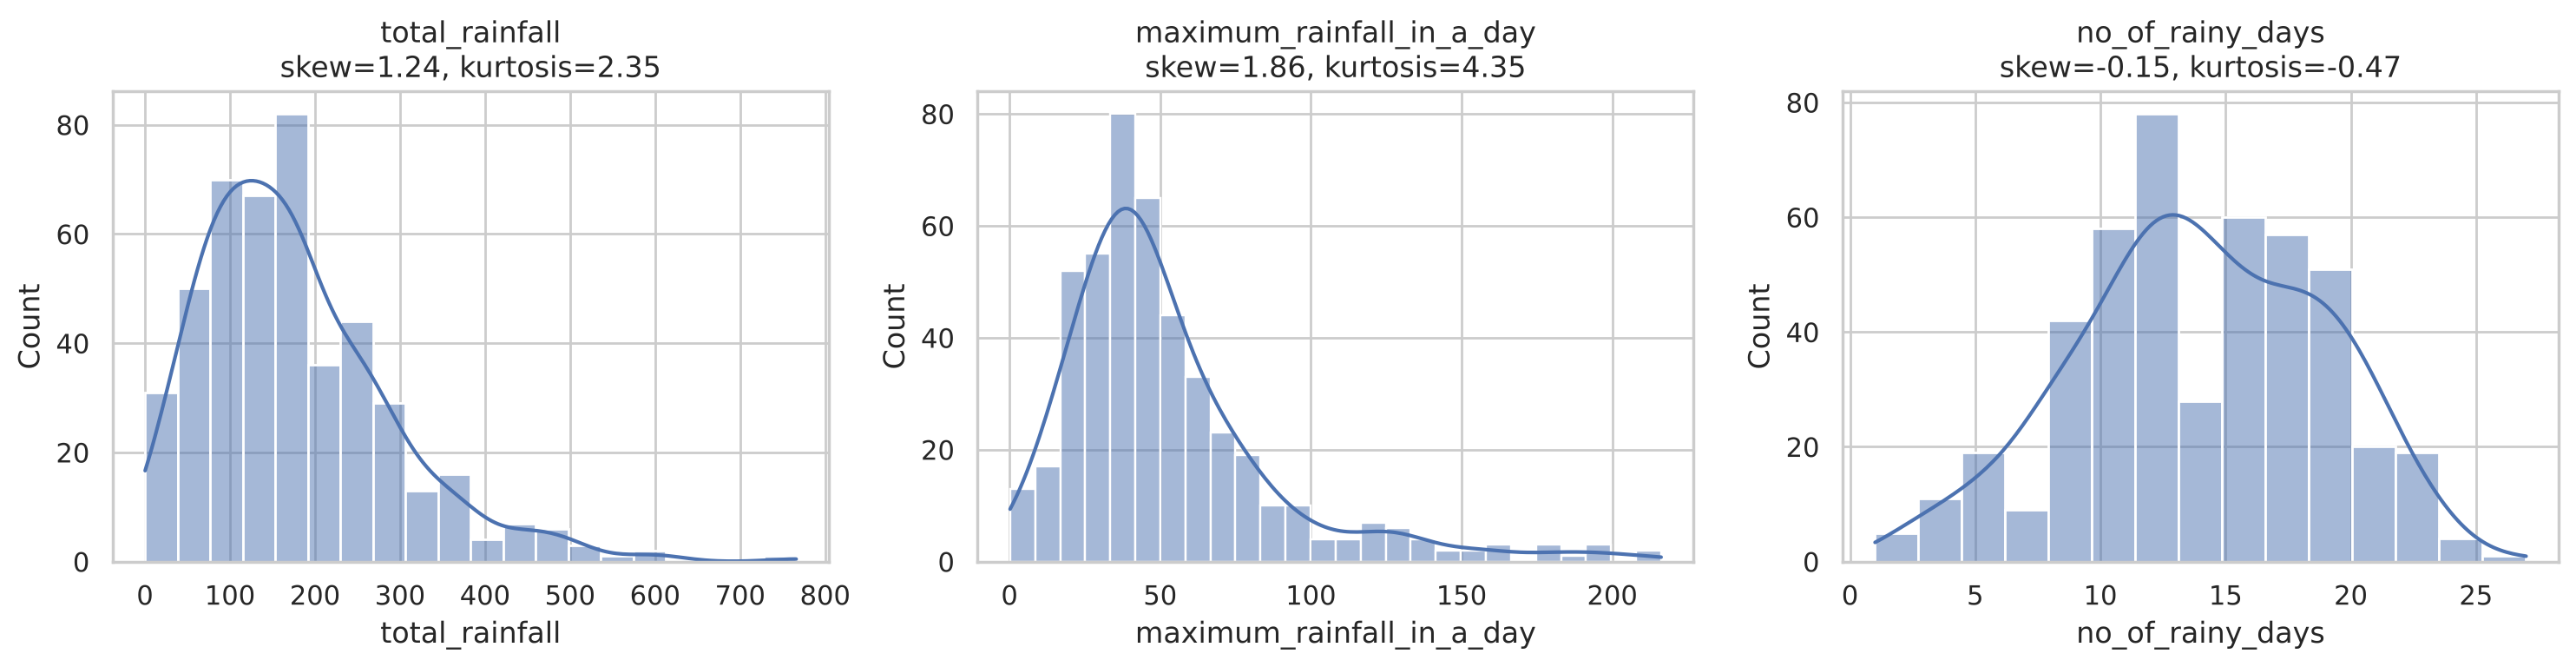

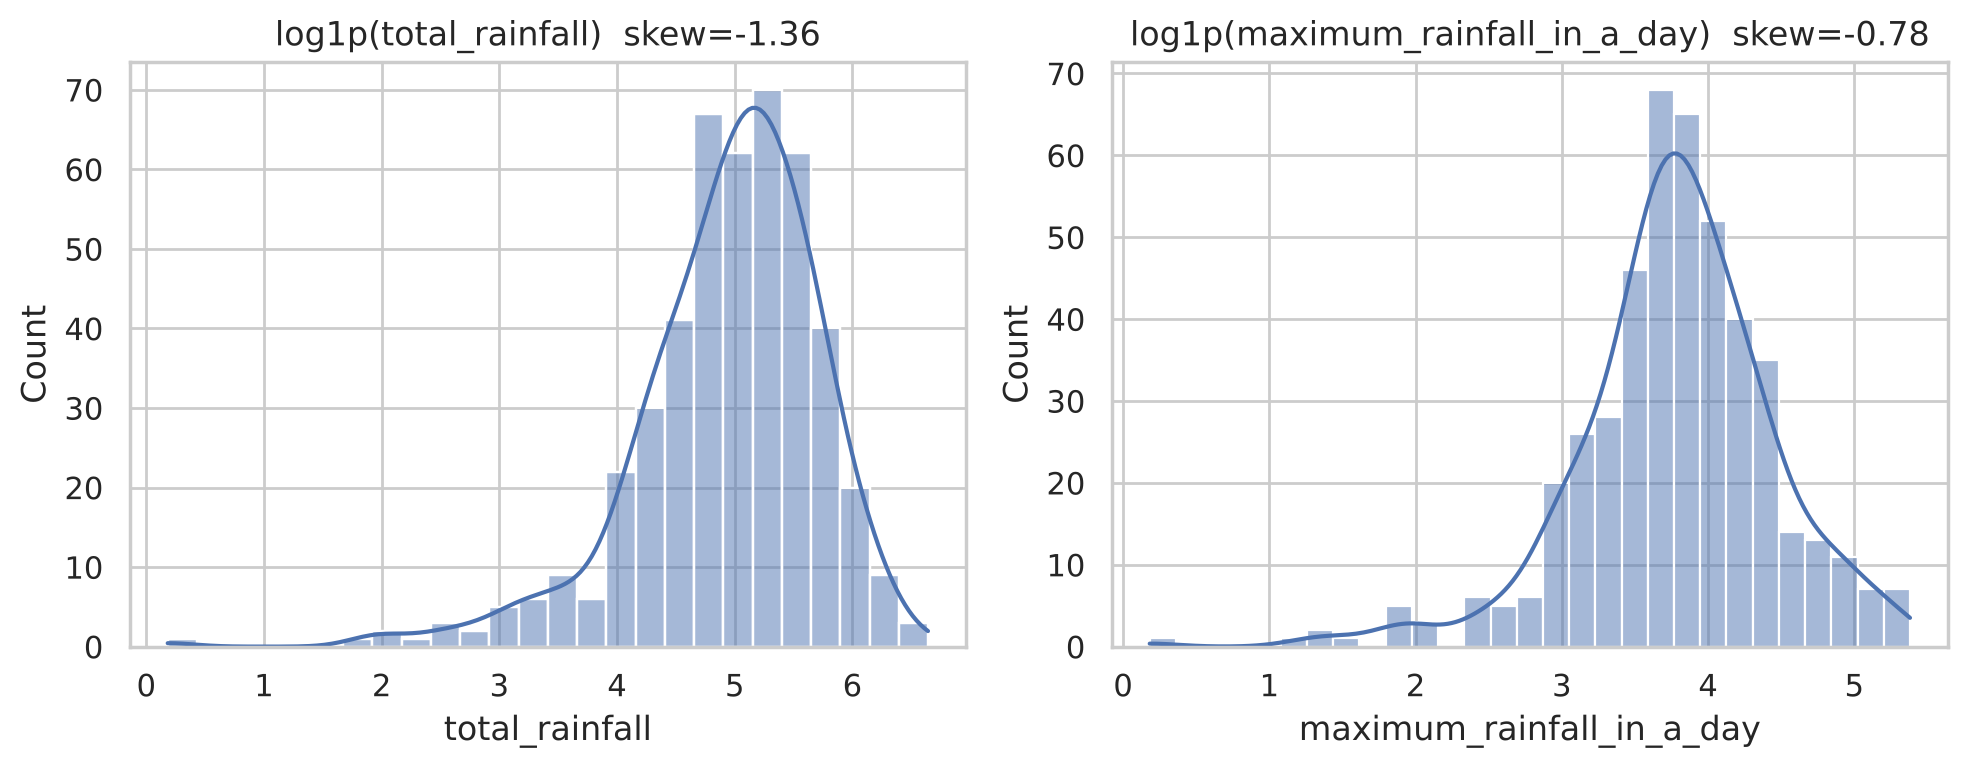

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days']):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'{col}\nskew={df[col].skew():.2f}, kurtosis={df[col].kurt():.2f}')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    sns.histplot(np.log1p(df[col]), kde=True, ax=ax)
    ax.set_title(f'log1p({col})  skew={np.log1p(df[col]).skew():.2f}')
plt.tight_layout(); plt.show()

Both rainfall targets are **right-skewed** with heavy tails (a few very wet months). A `log1p` transform makes
them much more symmetric, so the ML and deep learning models are trained on `log1p(target)` and predictions are
transformed back with `expm1`.

### 3.3 Seasonality: distribution by calendar month

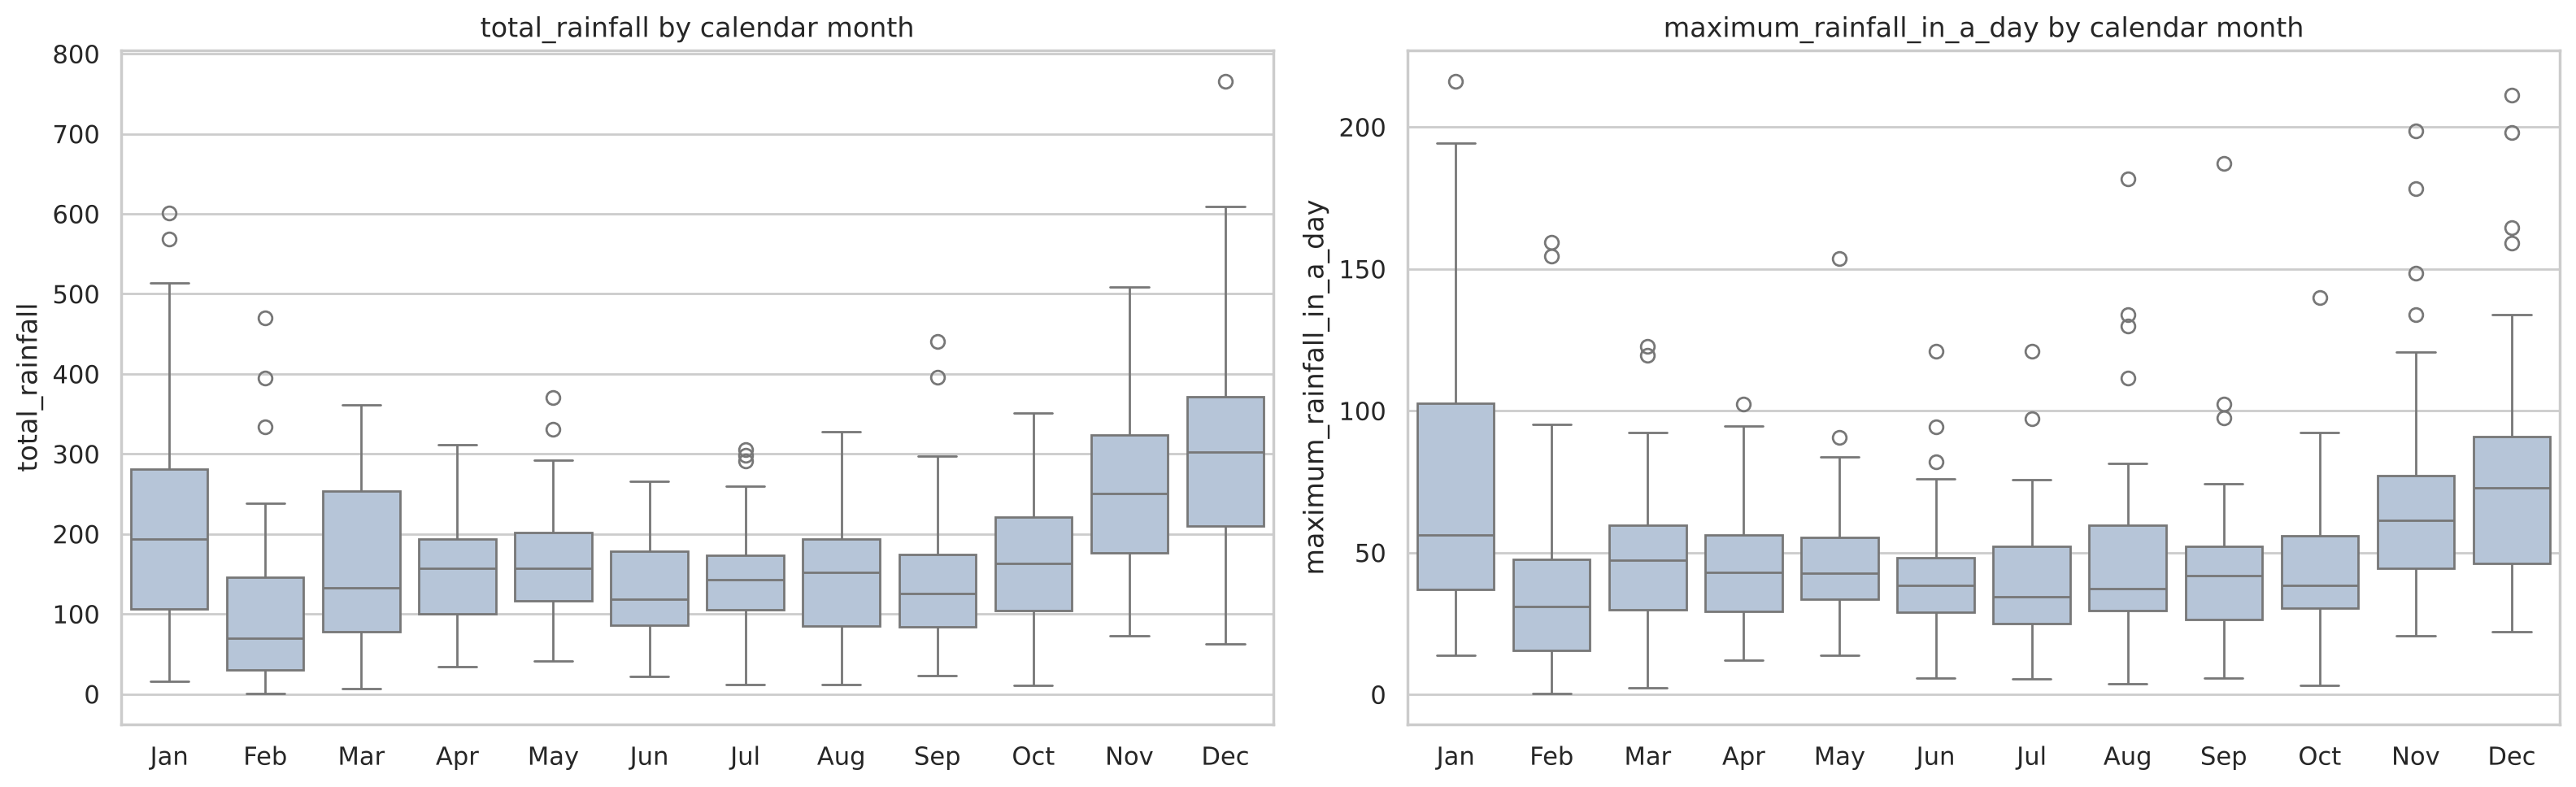

total_rainfall               maximum_rainfall_in_a_day               \
              mean median    std                      mean median   std   
Jan         226.00 193.90 152.80                     74.50  56.20 50.60   
Feb         104.70  69.20 107.00                     38.70  31.00 35.60   
Mar         160.30 132.50 103.20                     47.60  47.40 25.50   
Apr         153.00 157.00  67.70                     45.70  42.90 22.10   
May         165.80 157.50  75.30                     48.50  42.80 26.10   
Jun         134.30 118.30  65.70                     43.60  38.40 23.00   
Jul         146.30 142.40  72.50                     40.50  34.40 23.40   
Aug         147.10 152.40  70.50                     49.20  37.20 36.50   
Sep         145.70 125.20  93.20                     45.10  41.80 31.70   
Oct         161.40 162.80  82.70                     44.10  38.30 25.50   
Nov         255.60 250.80 104.20                     70.80  61.40 39.80   
Dec         317.60 302.40 144.60                     80.50  72.70 45.60   

    no_of_rainy_days              
                mean median  std  
Jan            13.40  13.00 5.50  
Feb             8.30   8.00 5.00  
Mar            12.20  11.00 5.40  
Apr            14.40  14.00 3.70  
May            14.00  13.00 3.40  
Jun            12.90  13.00 3.00  
Jul            13.30  13.00 3.90  
Aug            13.70  13.00 3.60  
Sep            13.10  13.00 4.40  
Oct            14.90  16.00 4.50  
Nov            18.90  19.00 3.60  
Dec            18.70  19.00 3.30

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    sns.boxplot(data=df, x='month_name', y=col, order=MONTH_ORDER, ax=ax, color='lightsteelblue')
    ax.set_title(f'{col} by calendar month'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

monthly_profile = df.groupby('month_num')[[TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days']].agg(['mean', 'median', 'std'])
monthly_profile.index = MONTH_ORDER
monthly_profile.round(1)

A clear seasonal cycle consistent with Singapore's monsoon climate:
- **November–January (Northeast Monsoon)** are the wettest months; December has the highest mean total.
- **February** is the driest month.
- The spread within each month is very large (for example, January's standard deviation is about two-thirds of
  its mean), so the calendar month explains only part of the variation.

### 3.4 Year × month heatmap

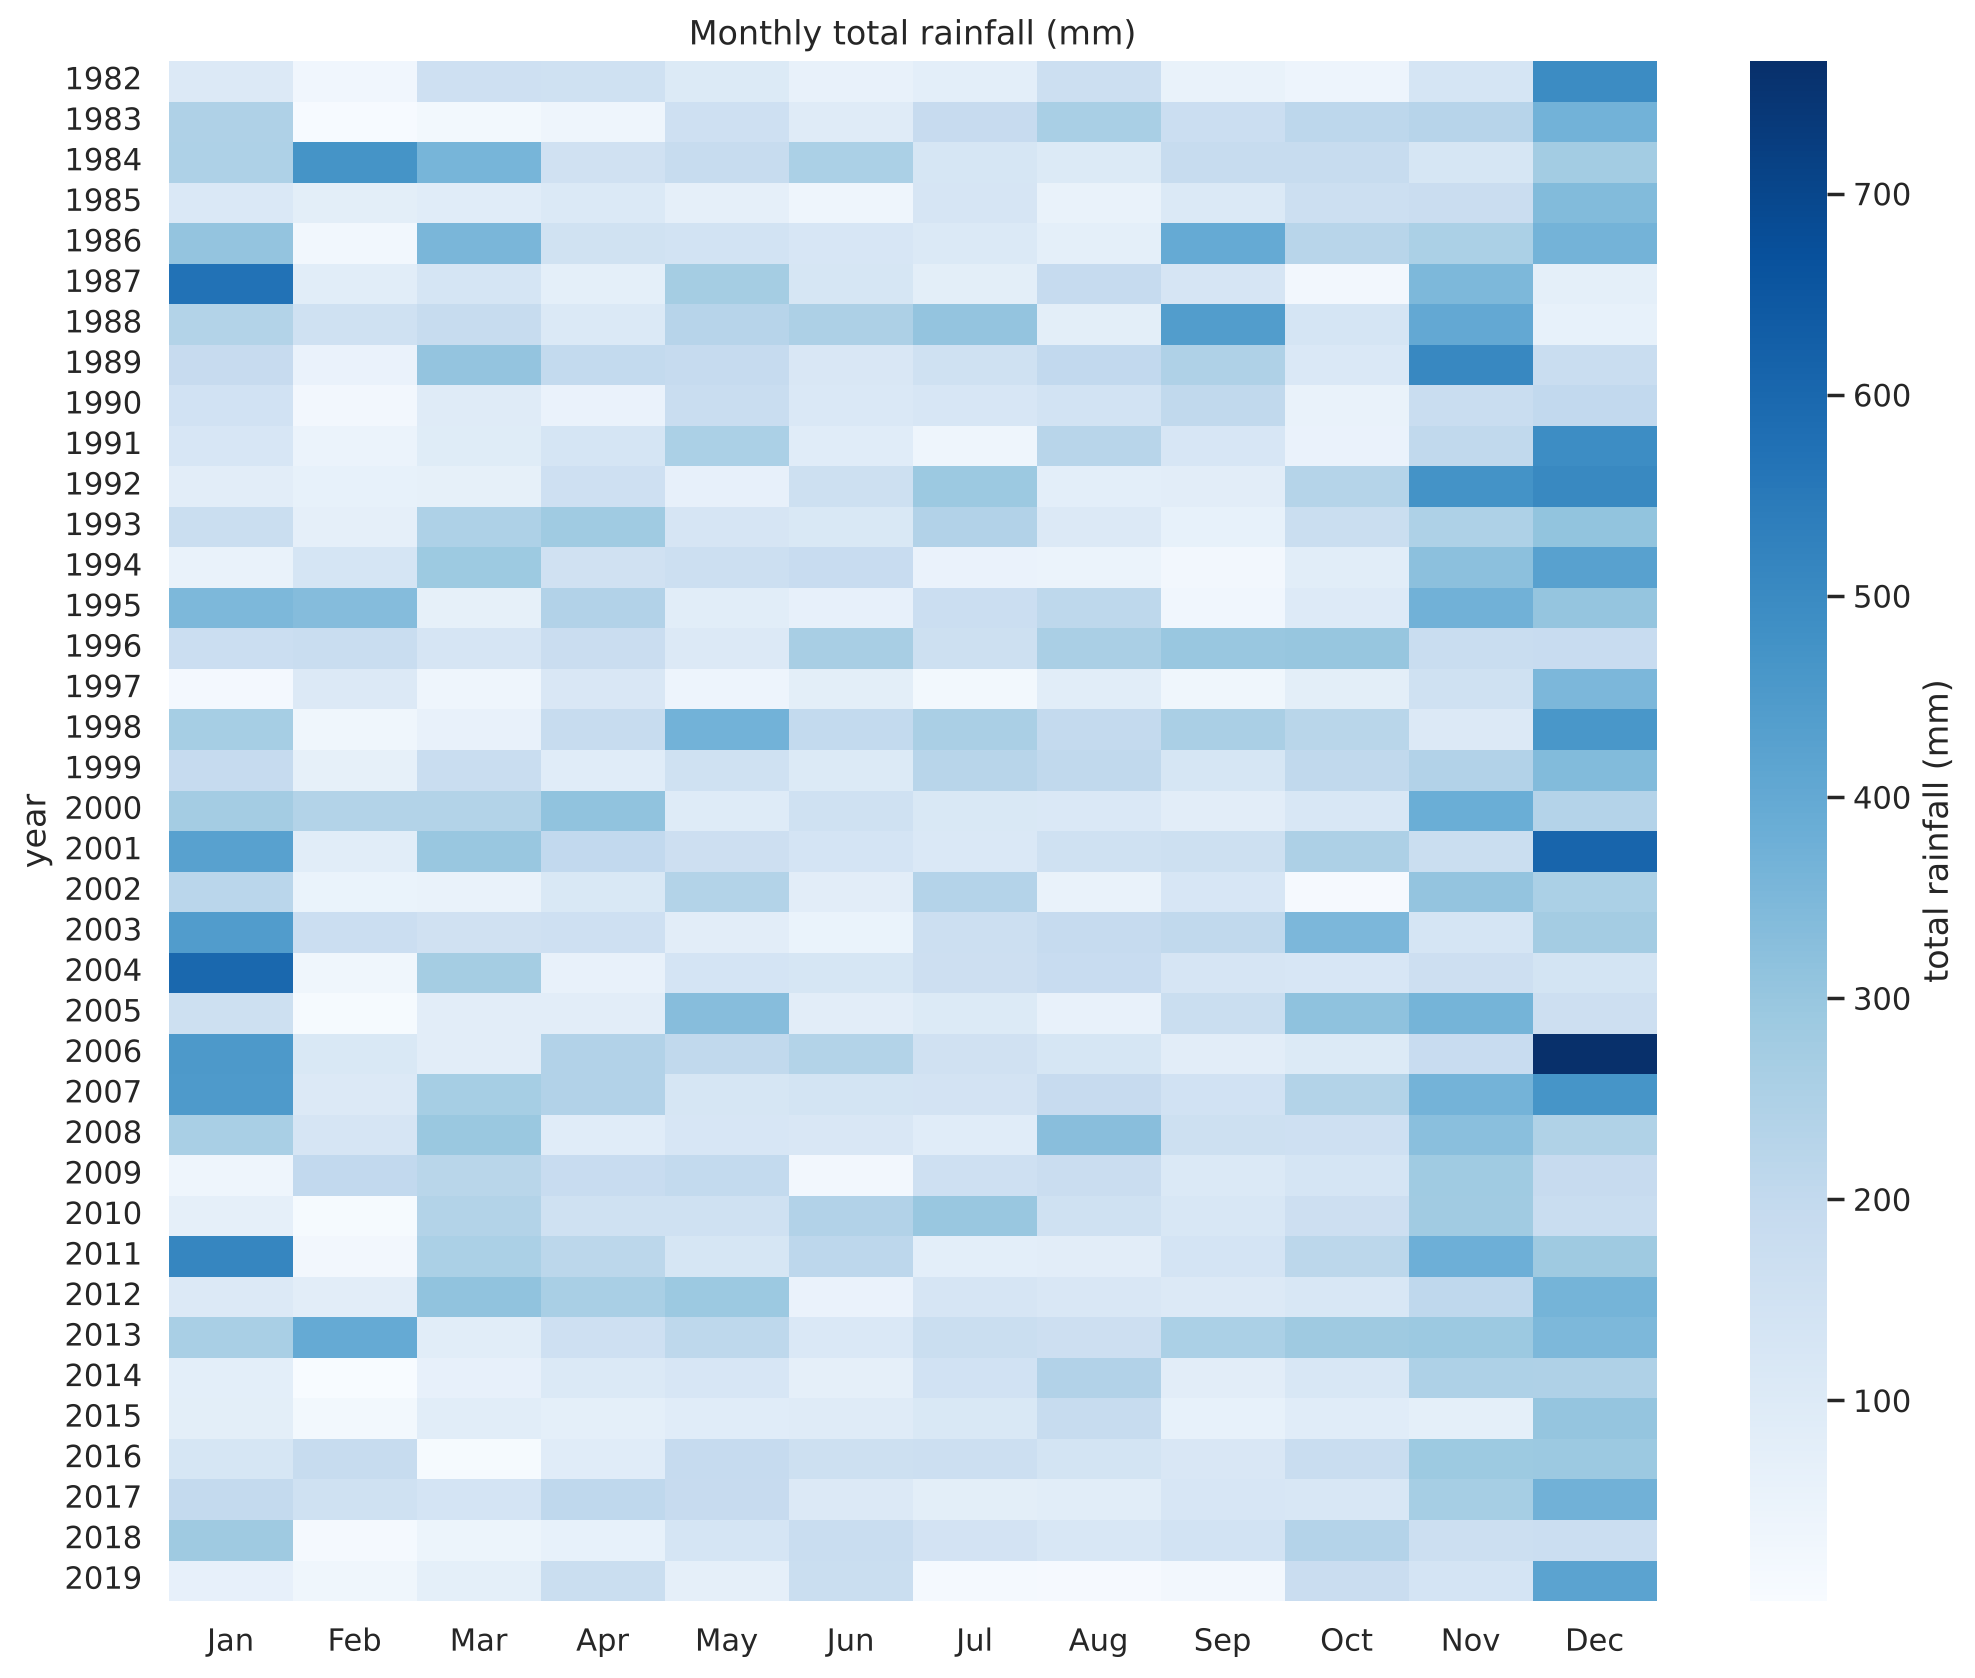

In [8]:
pivot = df[df.year < 2020].pivot_table(index='year', columns='month_num', values=TARGET_TOTAL)
pivot.columns = MONTH_ORDER
plt.figure(figsize=(12, 10))
sns.heatmap(pivot, cmap='Blues', cbar_kws={'label': 'total rainfall (mm)'})
plt.title('Monthly total rainfall (mm)'); plt.show()

### 3.5 Annual totals and long-term trend

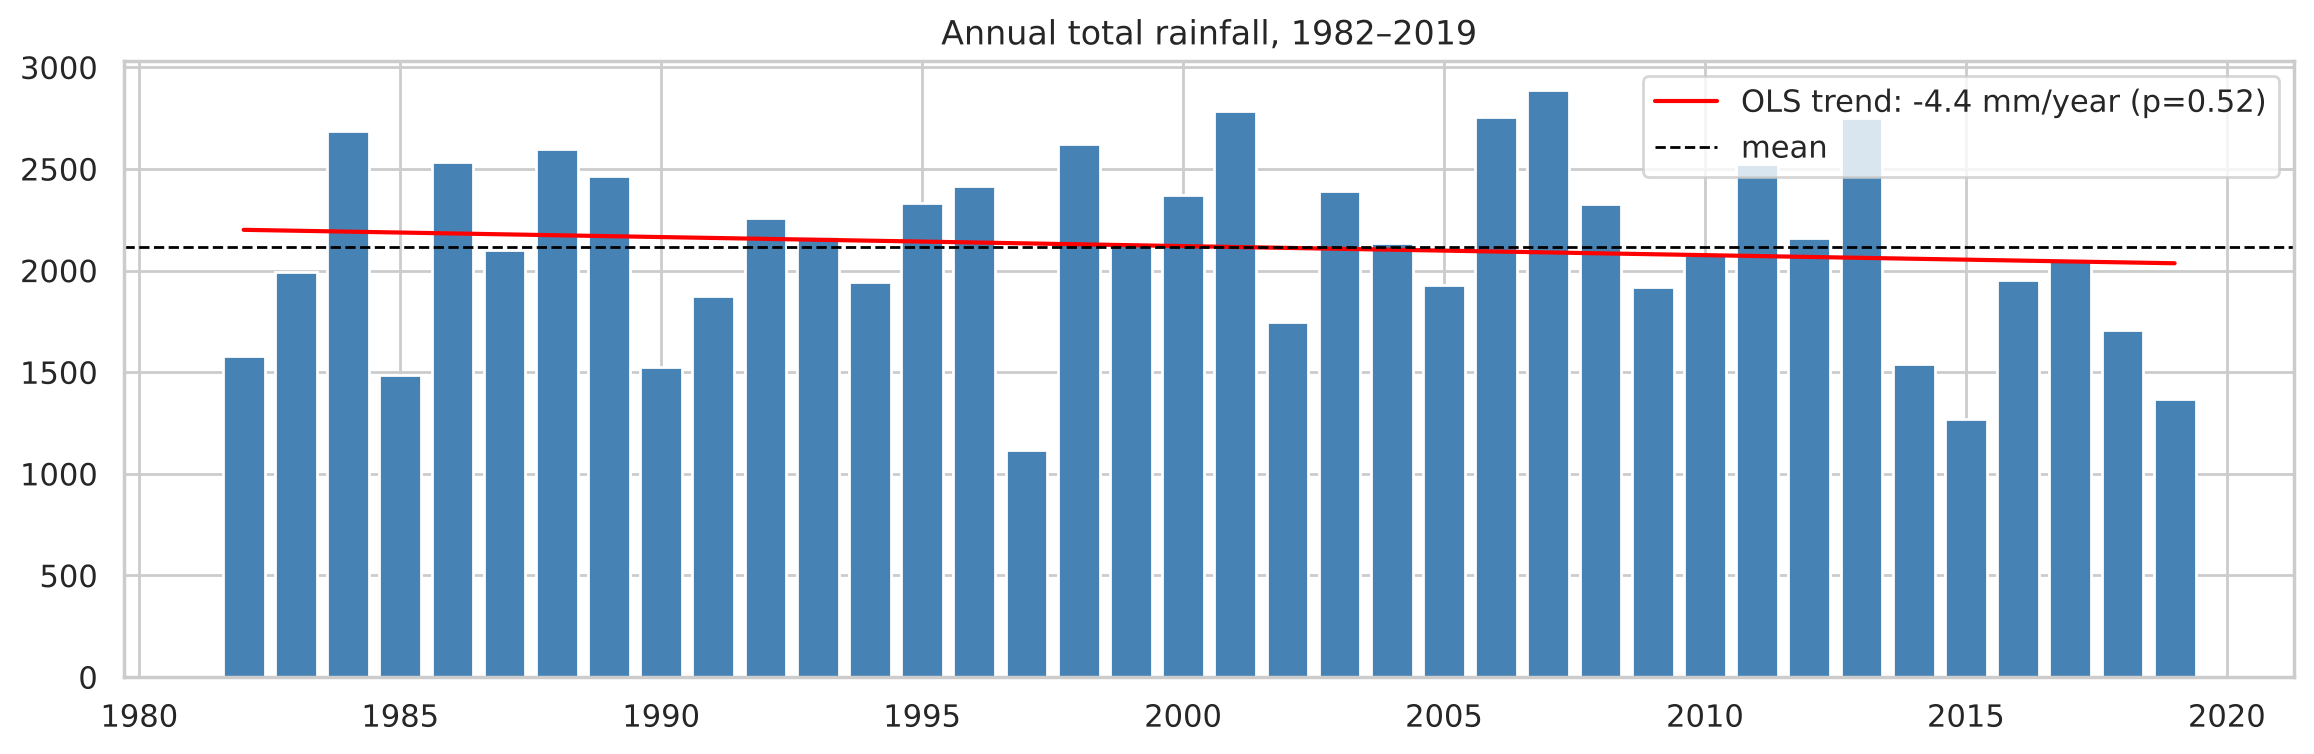

count      38.00
mean    2,118.00
std       454.00
min     1,119.00
25%     1,888.00
50%     2,135.00
75%     2,452.00
max     2,886.00
Name: total_rainfall, dtype: float64


In [9]:
annual = df[df.year < 2020].groupby('year')[[TARGET_TOTAL]].sum()
annual['max_day_of_year'] = df[df.year < 2020].groupby('year')[TARGET_MAX].max()

X_year = sm.add_constant(annual.index.values)
trend_fit = sm.OLS(annual[TARGET_TOTAL].values, X_year).fit()
slope, p_value = trend_fit.params[1], trend_fit.pvalues[1]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(annual.index, annual[TARGET_TOTAL], color='steelblue')
ax.plot(annual.index, trend_fit.fittedvalues, color='red', label=f'OLS trend: {slope:+.1f} mm/year (p={p_value:.2f})')
ax.axhline(annual[TARGET_TOTAL].mean(), color='black', ls='--', lw=1, label='mean')
ax.set_title('Annual total rainfall, 1982–2019'); ax.legend(); plt.show()
print(annual[TARGET_TOTAL].describe().round(0))

Annual rainfall varies widely between years. The linear trend over 1982–2019 is small relative to this
variation; its p-value (printed in the chart legend) shows whether it is statistically significant.
Year-to-year swings of this size are typical of large-scale climate drivers such as El Niño / La Niña,
which are not in this dataset.

### 3.6 Relationship between the three series

                           total_rainfall  maximum_rainfall_in_a_day  \
total_rainfall                       1.00                       0.80   
maximum_rainfall_in_a_day            0.80                       1.00   
no_of_rainy_days                     0.70                       0.41   

                           no_of_rainy_days  
total_rainfall                         0.70  
maximum_rainfall_in_a_day              0.41  
no_of_rainy_days                       1.00  


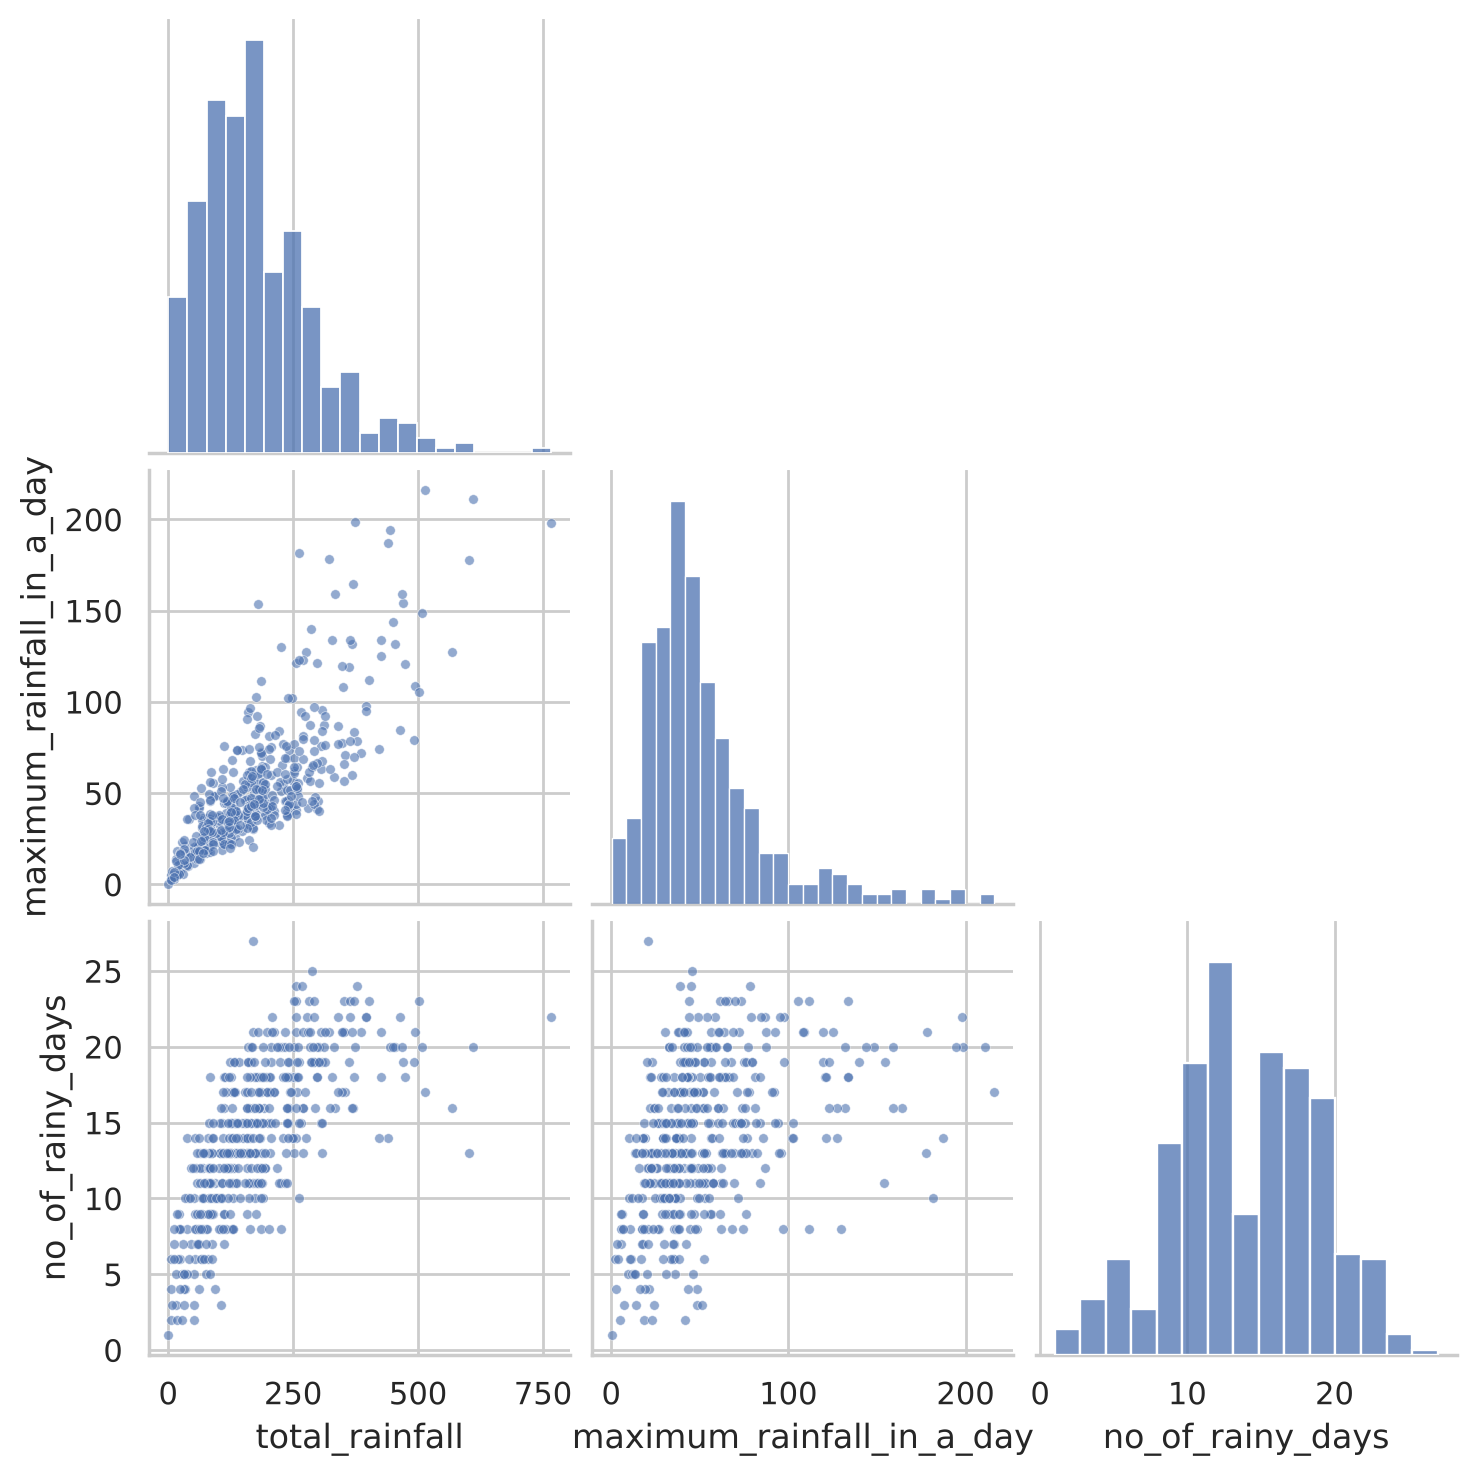

On average the wettest day contributes 33% of the month's rainfall (median 30%).


In [10]:
print(df[[TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days']].corr().round(2))
g = sns.pairplot(df[[TARGET_TOTAL, TARGET_MAX, 'no_of_rainy_days']], corner=True, plot_kws={'s': 12, 'alpha': 0.6})
plt.show()
share = df[TARGET_MAX] / df[TARGET_TOTAL]
print(f'On average the wettest day contributes {share.mean():.0%} of the month\'s rainfall (median {share.median():.0%}).')

The monthly maximum is strongly correlated with the monthly total: a single heavy-rain day typically supplies
about a third of the month's rainfall. The number of rain days is also correlated with the total, but it is
**not used as a model input**: when forecasting next year, the future number of rain days is as unknown as the
rainfall itself, so using it would leak information.

### 3.7 Outliers

In [11]:
def iqr_outliers(series, groups):
    q1 = series.groupby(groups).transform(lambda x: x.quantile(0.25))
    q3 = series.groupby(groups).transform(lambda x: x.quantile(0.75))
    iqr = q3 - q1
    return (series > q3 + 1.5 * iqr) | (series < q1 - 1.5 * iqr)

for col in [TARGET_TOTAL, TARGET_MAX]:
    flag = iqr_outliers(df[col], df['month_num'])
    print(f'{col}: {flag.sum()} outlier months ({flag.mean():.1%}) using a within-month 1.5×IQR rule')
    print(df.loc[flag, [col]].sort_values(col, ascending=False).head(5).to_string(), '\n')

total_rainfall: 13 outlier months (2.8%) using a within-month 1.5×IQR rule
            total_rainfall
month                     
2006-12-01          765.90
2004-01-01          600.90
1987-01-01          568.60
1984-02-01          470.40
1988-09-01          440.40 

maximum_rainfall_in_a_day: 29 outlier months (6.3%) using a within-month 1.5×IQR rule
            maximum_rainfall_in_a_day
month                                
2011-01-01                     216.20
2001-12-01                     211.10
1995-11-01                     198.60
2006-12-01                     198.00
1988-09-01                     187.30 



The flagged months (for example December 2006 and January 2011) are **genuine extreme rainfall events**, not
recording errors. They are kept: removing or capping them would make the models systematically under-predict
exactly the events that matter most, especially for the maximum-daily-rainfall target. Their influence is
reduced instead by the `log1p` transform and by using MAE as the main metric.

## 4. Hypothesis testing

**Question 1: Is rainfall the same in every calendar month?**
- H0: all twelve months have the same distribution of rainfall.
- H1: at least one month differs.

Normality is checked first with Shapiro-Wilk. One-way ANOVA assumes normality, so the non-parametric
Kruskal-Wallis test is also reported.

In [12]:
for col in [TARGET_TOTAL, TARGET_MAX]:
    groups = [g[col].values for _, g in df.groupby('month_num')]
    normal_share = np.mean([stats.shapiro(g).pvalue > 0.05 for g in groups])
    f_stat, p_anova = stats.f_oneway(*groups)
    h_stat, p_kw = stats.kruskal(*groups)
    print(f'{col}')
    print(f'  months passing Shapiro-Wilk normality (p>0.05): {normal_share:.0%}')
    print(f'  One-way ANOVA   F={f_stat:6.2f}  p={p_anova:.2e}')
    print(f'  Kruskal-Wallis  H={h_stat:6.2f}  p={p_kw:.2e}')

total_rainfall
  months passing Shapiro-Wilk normality (p>0.05): 67%
  One-way ANOVA   F= 14.00  p=3.02e-23
  Kruskal-Wallis  H=100.87  p=1.20e-16
maximum_rainfall_in_a_day
  months passing Shapiro-Wilk normality (p>0.05): 8%
  One-way ANOVA   F=  7.02  p=5.05e-11
  Kruskal-Wallis  H= 66.99  p=4.55e-10


**Question 2: Is the Northeast Monsoon (Dec–Jan) wetter than the Southwest Monsoon (Jun–Sep)?**
- H0: mean monthly rainfall is equal in the two seasons.
- H1: the means differ. (Welch's two-sample independent t-test, which does not assume equal variances.)

In [13]:
ne = df.loc[df.month_num.isin([12, 1]), TARGET_TOTAL]
sw = df.loc[df.month_num.isin([6, 7, 8, 9]), TARGET_TOTAL]
t_stat, p_t = stats.ttest_ind(ne, sw, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(ne, sw, alternative='two-sided')
print(f'NE monsoon mean = {ne.mean():.1f} mm, SW monsoon mean = {sw.mean():.1f} mm')
print(f"Welch t-test     t={t_stat:.2f}  p={p_t:.2e}")
print(f'Mann-Whitney U   U={u_stat:.0f}  p={p_u:.2e}')

NE monsoon mean = 271.2 mm, SW monsoon mean = 143.3 mm
Welch t-test     t=6.85  p=7.40e-10
Mann-Whitney U   U=8974  p=9.55e-11


Both questions reject H0 at the 5% level: seasonality is statistically significant, so every forecasting
model must account for the calendar month. Most monthly distributions are not normal, which supports the
non-parametric tests and the log transform.

## 5. Time series analysis

### 5.1 Decomposition into trend, seasonality, cyclical and random components

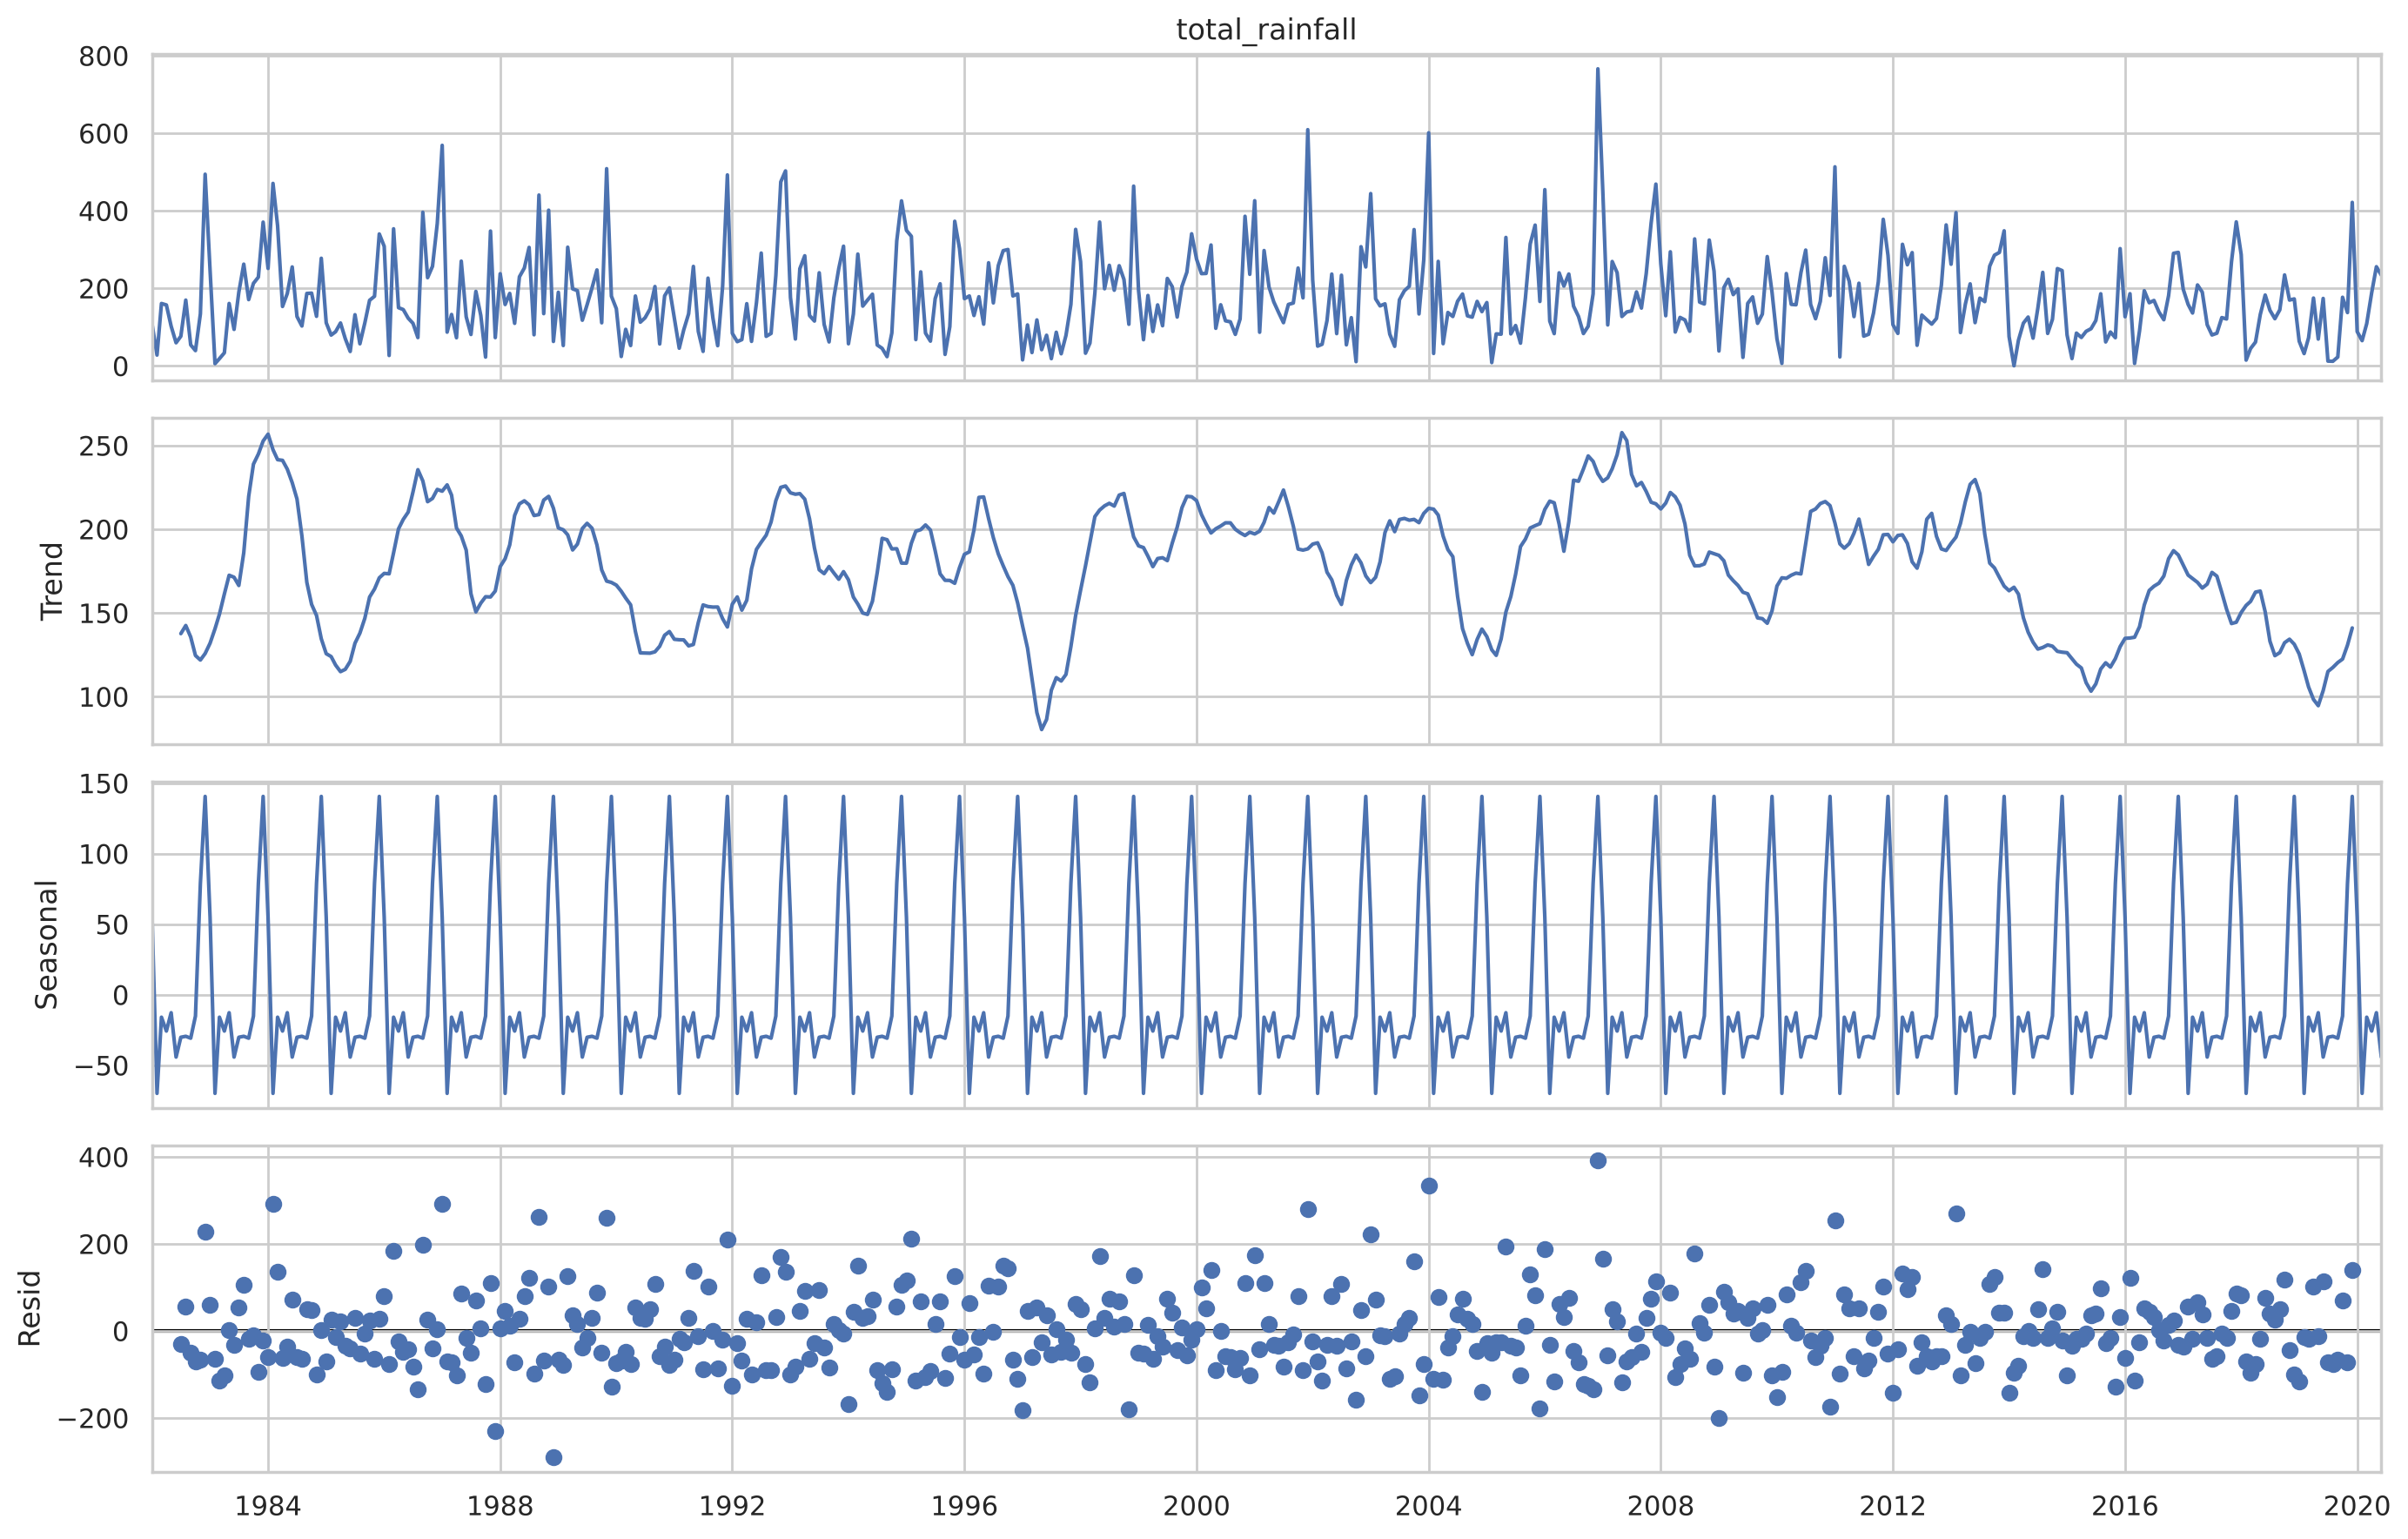

Share of variance (STL decomposition, approximate):
  seasonal component : 45%
  trend / cyclical   : 5%
  random (residual)  : 59%


In [14]:
decomp = seasonal_decompose(df[TARGET_TOTAL], model='additive', period=12)
fig = decomp.plot(); fig.set_size_inches(14, 9); plt.tight_layout(); plt.show()

stl = STL(df[TARGET_TOTAL], period=12, robust=True).fit()
var_resid = stl.resid.var(); var_seas = stl.seasonal.var(); var_trend = stl.trend.var()
total_var = df[TARGET_TOTAL].var()
print('Share of variance (STL decomposition, approximate):')
print(f'  seasonal component : {var_seas / total_var:.0%}')
print(f'  trend / cyclical   : {var_trend / total_var:.0%}')
print(f'  random (residual)  : {var_resid / total_var:.0%}')

- **Trend:** no persistent long-term direction (annual totals change by about −4 mm per year, p = 0.52, not significant).
- **Cyclical:** the slow multi-year waves in the trend line reflect wet and dry years (consistent with
  El Niño / La Niña cycles), but they are irregular and cannot be forecast from rainfall alone.
- **Seasonality:** a stable annual cycle.
- **Random:** the residual is the largest component (the shares above overlap, so they do not add to 100%). This sets a ceiling on how accurate any
  12-month-ahead forecast can be.

### 5.2 Stationarity tests (ADF and KPSS)

In [15]:
def stationarity_report(series, name):
    adf_stat, adf_p, *_ = adfuller(series.dropna(), autolag='AIC')
    kpss_stat, kpss_p, *_ = kpss(series.dropna(), regression='c', nlags='auto')
    verdict = 'stationary' if (adf_p < 0.05 and kpss_p > 0.05) else 'check'
    return {'series': name, 'ADF stat': adf_stat, 'ADF p': adf_p, 'KPSS stat': kpss_stat, 'KPSS p': kpss_p, 'verdict': verdict}

rows = []
for col in [TARGET_TOTAL, TARGET_MAX]:
    rows.append(stationarity_report(df[col], col))
    rows.append(stationarity_report(df[col].diff(12), f'{col} (seasonal diff 12)'))
pd.DataFrame(rows)

,series,ADF stat,ADF p,KPSS stat,KPSS p,verdict
0,total_rainfall,-5.32,0.00,0.16,0.10,stationary
1,total_rainfall (seasonal diff 12),-8.01,0.00,0.03,0.10,stationary
2,maximum_rainfall_in_a_day,-4.96,0.00,0.33,0.10,stationary
3,maximum_rainfall_in_a_day (seasonal diff 12),-10.91,0.00,0.03,0.10,stationary


ADF tests H0 = "unit root (non-stationary)"; KPSS tests H0 = "stationary". The raw series reject the ADF null
and do not reject the KPSS null, so they are **stationary in the mean**: no regular differencing (d = 0) is
needed. Seasonal differencing is therefore not applied either (D = 0).
(KPSS p-values are bounded to the range 0.01–0.10 by the lookup table.)

### 5.3 Autocorrelation (ACF) and partial autocorrelation (PACF)

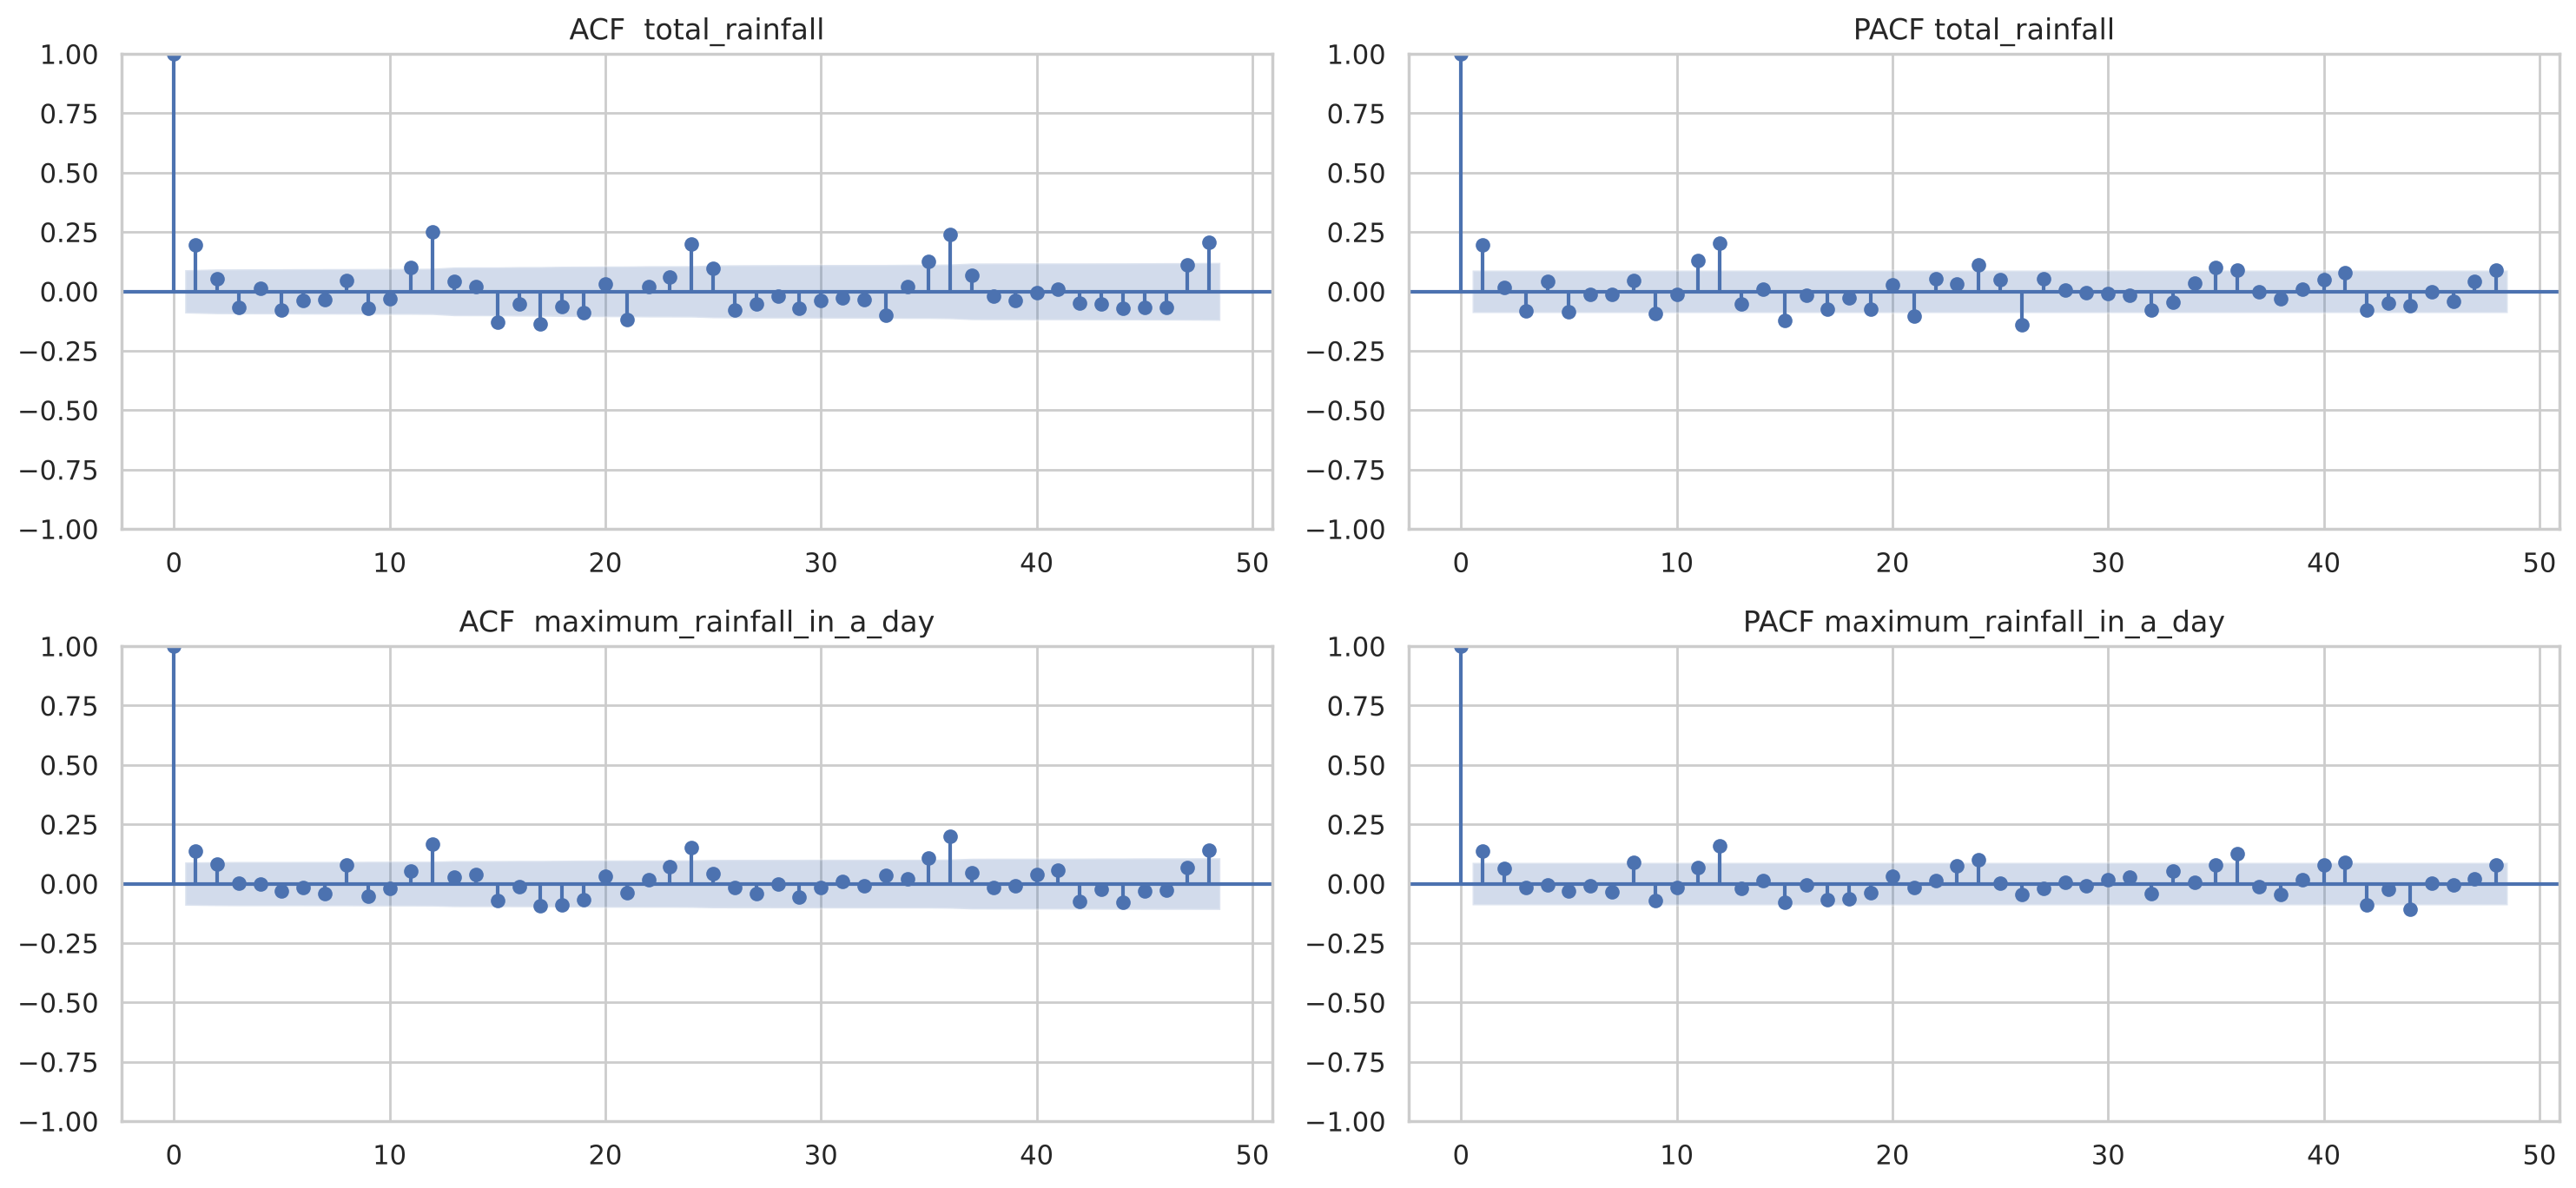

total_rainfall: autocorrelation lag 1 = 0.20, lag 12 = 0.26
maximum_rainfall_in_a_day: autocorrelation lag 1 = 0.14, lag 12 = 0.17


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for i, col in enumerate([TARGET_TOTAL, TARGET_MAX]):
    plot_acf(df[col], lags=48, ax=axes[i, 0], title=f'ACF  {col}')
    plot_pacf(df[col], lags=48, ax=axes[i, 1], title=f'PACF {col}', method='ywm')
plt.tight_layout(); plt.show()
for col in [TARGET_TOTAL, TARGET_MAX]:
    print(f'{col}: autocorrelation lag 1 = {df[col].autocorr(1):.2f}, lag 12 = {df[col].autocorr(12):.2f}')

Autocorrelations are **weak**: last month explains little about this month, and the same month last year
explains little more. Spikes at multiples of 12 confirm the seasonal pattern. This means:
- AR and MA terms will add little beyond seasonality.
- For a 12-month horizon, last month's value is not even available for most target months, so ML features
  must only use information that is at least 12 months old.

## 6. Evaluation design

The business question is a **12-month-ahead** forecast, so every model is evaluated exactly that way.

- **Rolling-origin backtest (model selection):** 9 forecast origins at the end of June 2010, 2011, …, 2018.
  At each origin a model is trained only on data up to that point and forecasts the next 12 months
  (July–June). 9 folds × 12 months = 108 out-of-sample forecasts per model.
- **Final holdout (not used to fit, tune or rank any model):** origin June 2019, forecasting July 2019 – June 2020. It is used only once,
  after the model has been chosen, to confirm the result.
- **Metrics:** MAE (main metric, in mm, robust to outliers), RMSE (penalises large misses), and
  **skill vs. seasonal naive** = 1 − MAE_model / MAE_seasonal_naive (positive = better than the naive forecast).

In [17]:
H = 12
BACKTEST_ORIGINS = [pd.Timestamp(f'{y}-06-01') for y in range(2010, 2019)]
HOLDOUT_ORIGIN = pd.Timestamp('2019-06-01')

def future_index(series, h=H):
    return pd.date_range(series.index[-1] + pd.offsets.MonthBegin(), periods=h, freq='MS')

def split_at(series, origin, h=H):
    train = series[:origin]
    test = series[origin + pd.offsets.MonthBegin():].iloc[:h]
    return train, test

def evaluate(forecast_fn, series, origins):
    """Run a 12-month-ahead forecast from each origin; return per-fold errors and all predictions."""
    preds, fold_mae = [], []
    for origin in origins:
        train, test = split_at(series, origin)
        yhat = np.asarray(forecast_fn(train), dtype=float)[:len(test)]
        preds.append(pd.DataFrame({'actual': test.values, 'pred': yhat}, index=test.index))
        fold_mae.append(np.mean(np.abs(test.values - yhat)))
    preds = pd.concat(preds)
    err = preds['actual'] - preds['pred']
    return {'MAE': np.mean(np.abs(err)), 'RMSE': np.sqrt(np.mean(err ** 2)),
            'fold_MAE_std': np.std(fold_mae), 'preds': preds}

RESULTS = {TARGET_TOTAL: {}, TARGET_MAX: {}}

def run_model(name, forecast_fn, targets=(TARGET_TOTAL, TARGET_MAX)):
    for col in targets:
        RESULTS[col][name] = {'fn': forecast_fn,
                              'backtest': evaluate(forecast_fn, df[col], BACKTEST_ORIGINS)}
    return pd.DataFrame({col: {'MAE': RESULTS[col][name]['backtest']['MAE'],
                               'RMSE': RESULTS[col][name]['backtest']['RMSE']} for col in targets}).T

def leaderboard(col):
    base = RESULTS[col]['Seasonal naive']['backtest']['MAE']
    rows = [{'model': n, 'MAE': r['backtest']['MAE'], 'RMSE': r['backtest']['RMSE'],
             'fold MAE std': r['backtest']['fold_MAE_std'], 'skill vs naive': 1 - r['backtest']['MAE'] / base}
            for n, r in RESULTS[col].items()]
    return pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)

## 7. Baseline models

Any useful model must beat these simple rules:
- **Seasonal naive:** next year's month = the same month last year.
- **Monthly mean / monthly median (climatology):** the historical average (or median) of that calendar month.

In [18]:
def seasonal_naive(train):
    return train.iloc[-12:].values

def monthly_mean(train):
    profile = train.groupby(train.index.month).mean()
    return profile.loc[future_index(train).month].values

def monthly_median(train):
    profile = train.groupby(train.index.month).median()
    return profile.loc[future_index(train).month].values

for name, fn in [('Seasonal naive', seasonal_naive), ('Monthly mean', monthly_mean), ('Monthly median', monthly_median)]:
    print(name); print(run_model(name, fn).round(1), '\n')

Seasonal naive
                            MAE   RMSE
total_rainfall            86.20 119.30
maximum_rainfall_in_a_day 28.80  43.10 

Monthly mean
                            MAE  RMSE
total_rainfall            67.30 85.50
maximum_rainfall_in_a_day 22.40 30.20 

Monthly median
                            MAE  RMSE
total_rainfall            63.90 83.20
maximum_rainfall_in_a_day 19.30 28.30 



## 8. Statistical time series models: AR, MA, ARIMA, SARIMA, Holt-Winters

Orders are selected by **AIC** (Akaike Information Criterion: lower = better trade-off between fit and
complexity) on the data available **before the first backtest origin** (1982 – June 2010), so selection does
not see any test data.

**Differencing is fixed, not searched.** Section 5.2 shows both series are stationary, so `d = 0` and `D = 0`.
AIC values are only comparable between models fitted to the *same* data: a model with differencing drops its
first observations from the likelihood, so comparing it with an undifferenced model by AIC is invalid (and
tends to favour over-differenced models). The ARIMA search is therefore over `(p, 0, q)` and the SARIMA search
over `(p, 0, q)(P, 0, Q, 12)`. Stationarity and invertibility are enforced so the fitted models are well-defined.

In [19]:
selection_data = {col: df[col][:BACKTEST_ORIGINS[0]] for col in [TARGET_TOTAL, TARGET_MAX]}

def fit_sarimax(series, order, seasonal_order=(0, 0, 0, 0)):
    return SARIMAX(series, order=order, seasonal_order=seasonal_order, trend='c',
                   enforce_stationarity=True, enforce_invertibility=True).fit(disp=False, maxiter=200)

def aic_search(series, orders, seasonal_orders=((0, 0, 0, 0),)):
    rows = []
    for o, so in itertools.product(orders, seasonal_orders):
        try:
            rows.append({'order': o, 'seasonal_order': so, 'AIC': fit_sarimax(series, o, so).aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

best_orders = {}
for col in [TARGET_TOTAL, TARGET_MAX]:
    s = selection_data[col]
    ar = aic_search(s, [(p, 0, 0) for p in range(1, 7)])
    ma = aic_search(s, [(0, 0, q) for q in range(1, 7)])
    arima = aic_search(s, [(p, 0, q) for p in range(3) for q in range(3) if p + q > 0])
    sarima = aic_search(s, [(p, 0, q) for p in range(3) for q in range(3)],
                        [(P, 0, Q, 12) for P in range(3) for Q in range(3) if P + Q > 0])
    best_orders[col] = {'AR': ar.iloc[0], 'MA': ma.iloc[0], 'ARIMA': arima.iloc[0], 'SARIMA': sarima.iloc[0]}
    print(col)
    for k, r in best_orders[col].items():
        print(f"  best {k:6s}: order={r['order']} seasonal={r['seasonal_order']}  AIC={r['AIC']:.1f}")
    print('  top 5 SARIMA candidates:'); print(sarima.head().to_string(index=False), '\n')

total_rainfall
  best AR    : order=(1, 0, 0) seasonal=(0, 0, 0, 0)  AIC=4226.9
  best MA    : order=(0, 0, 1) seasonal=(0, 0, 0, 0)  AIC=4227.7
  best ARIMA : order=(1, 0, 0) seasonal=(0, 0, 0, 0)  AIC=4226.9
  best SARIMA: order=(2, 0, 1) seasonal=(1, 0, 1, 12)  AIC=4173.5
  top 5 SARIMA candidates:
    order seasonal_order      AIC
(2, 0, 1)  (1, 0, 1, 12) 4,173.53
(2, 0, 1)  (1, 0, 2, 12) 4,175.41
(2, 0, 1)  (2, 0, 1, 12) 4,175.45
(1, 0, 2)  (1, 0, 2, 12) 4,175.64
(1, 0, 2)  (2, 0, 1, 12) 4,175.64 



maximum_rainfall_in_a_day
  best AR    : order=(1, 0, 0) seasonal=(0, 0, 0, 0)  AIC=3449.0
  best MA    : order=(0, 0, 1) seasonal=(0, 0, 0, 0)  AIC=3449.6
  best ARIMA : order=(1, 0, 0) seasonal=(0, 0, 0, 0)  AIC=3449.0
  best SARIMA: order=(1, 0, 2) seasonal=(1, 0, 1, 12)  AIC=3424.0
  top 5 SARIMA candidates:
    order seasonal_order      AIC
(1, 0, 2)  (1, 0, 1, 12) 3,424.05
(0, 0, 2)  (1, 0, 1, 12) 3,424.46
(2, 0, 0)  (2, 0, 1, 12) 3,424.54
(2, 0, 0)  (1, 0, 2, 12) 3,424.69
(0, 0, 2)  (2, 0, 1, 12) 3,424.88 



In [20]:
def make_sarimax_forecaster(order, seasonal_order):
    def forecast(train):
        return fit_sarimax(train, order, seasonal_order).forecast(H).values
    return forecast

def holt_winters(train):
    return ExponentialSmoothing(train, trend=None, seasonal='add', seasonal_periods=12).fit().forecast(H).values

for model_type in ['AR', 'MA', 'ARIMA', 'SARIMA']:
    for col in [TARGET_TOTAL, TARGET_MAX]:
        r = best_orders[col][model_type]
        fn = make_sarimax_forecaster(r['order'], r['seasonal_order'])
        RESULTS[col][model_type] = {'fn': fn, 'backtest': evaluate(fn, df[col], BACKTEST_ORIGINS),
                                    'spec': (r['order'], r['seasonal_order'])}
print(run_model('Holt-Winters', holt_winters).round(1))
hw_fit = ExponentialSmoothing(selection_data[TARGET_TOTAL], seasonal='add', seasonal_periods=12).fit()
print('Holt-Winters fitted smoothing parameters (total rainfall):',
      {k: round(float(v), 3) for k, v in hw_fit.params.items() if k in ('smoothing_level', 'smoothing_seasonal')})

                            MAE  RMSE
total_rainfall            67.30 85.50
maximum_rainfall_in_a_day 22.40 30.20
Holt-Winters fitted smoothing parameters (total rainfall): {'smoothing_level': 0.0, 'smoothing_seasonal': 0.0}


Holt-Winters chooses smoothing parameters of 0: the optimiser finds that recent values carry no useful
information, so the level and seasonal pattern never update. It then collapses to the **monthly mean**, which
is why the two rows are identical in the leaderboard. This is itself evidence of how little month-to-month
memory these series have.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.3253      2.785      0.117      0.907      -5.133       5.784
ar.L1         -0.8126      0.084     -9.636      0.000      -0.978      -0.647
ar.L2          0.1437      0.055      2.620      0.009       0.036       0.251
ma.L1          0.9190      0.070     13.159      0.000       0.782       1.056
ar.S.L12       0.9989      0.009    108.400      0.000       0.981       1.017
ma.S.L12      -0.9764      0.102     -9.571      0.000      -1.176      -0.776
sigma2       1.06e+04   1084.035      9.778      0.000    8474.725    1.27e+04


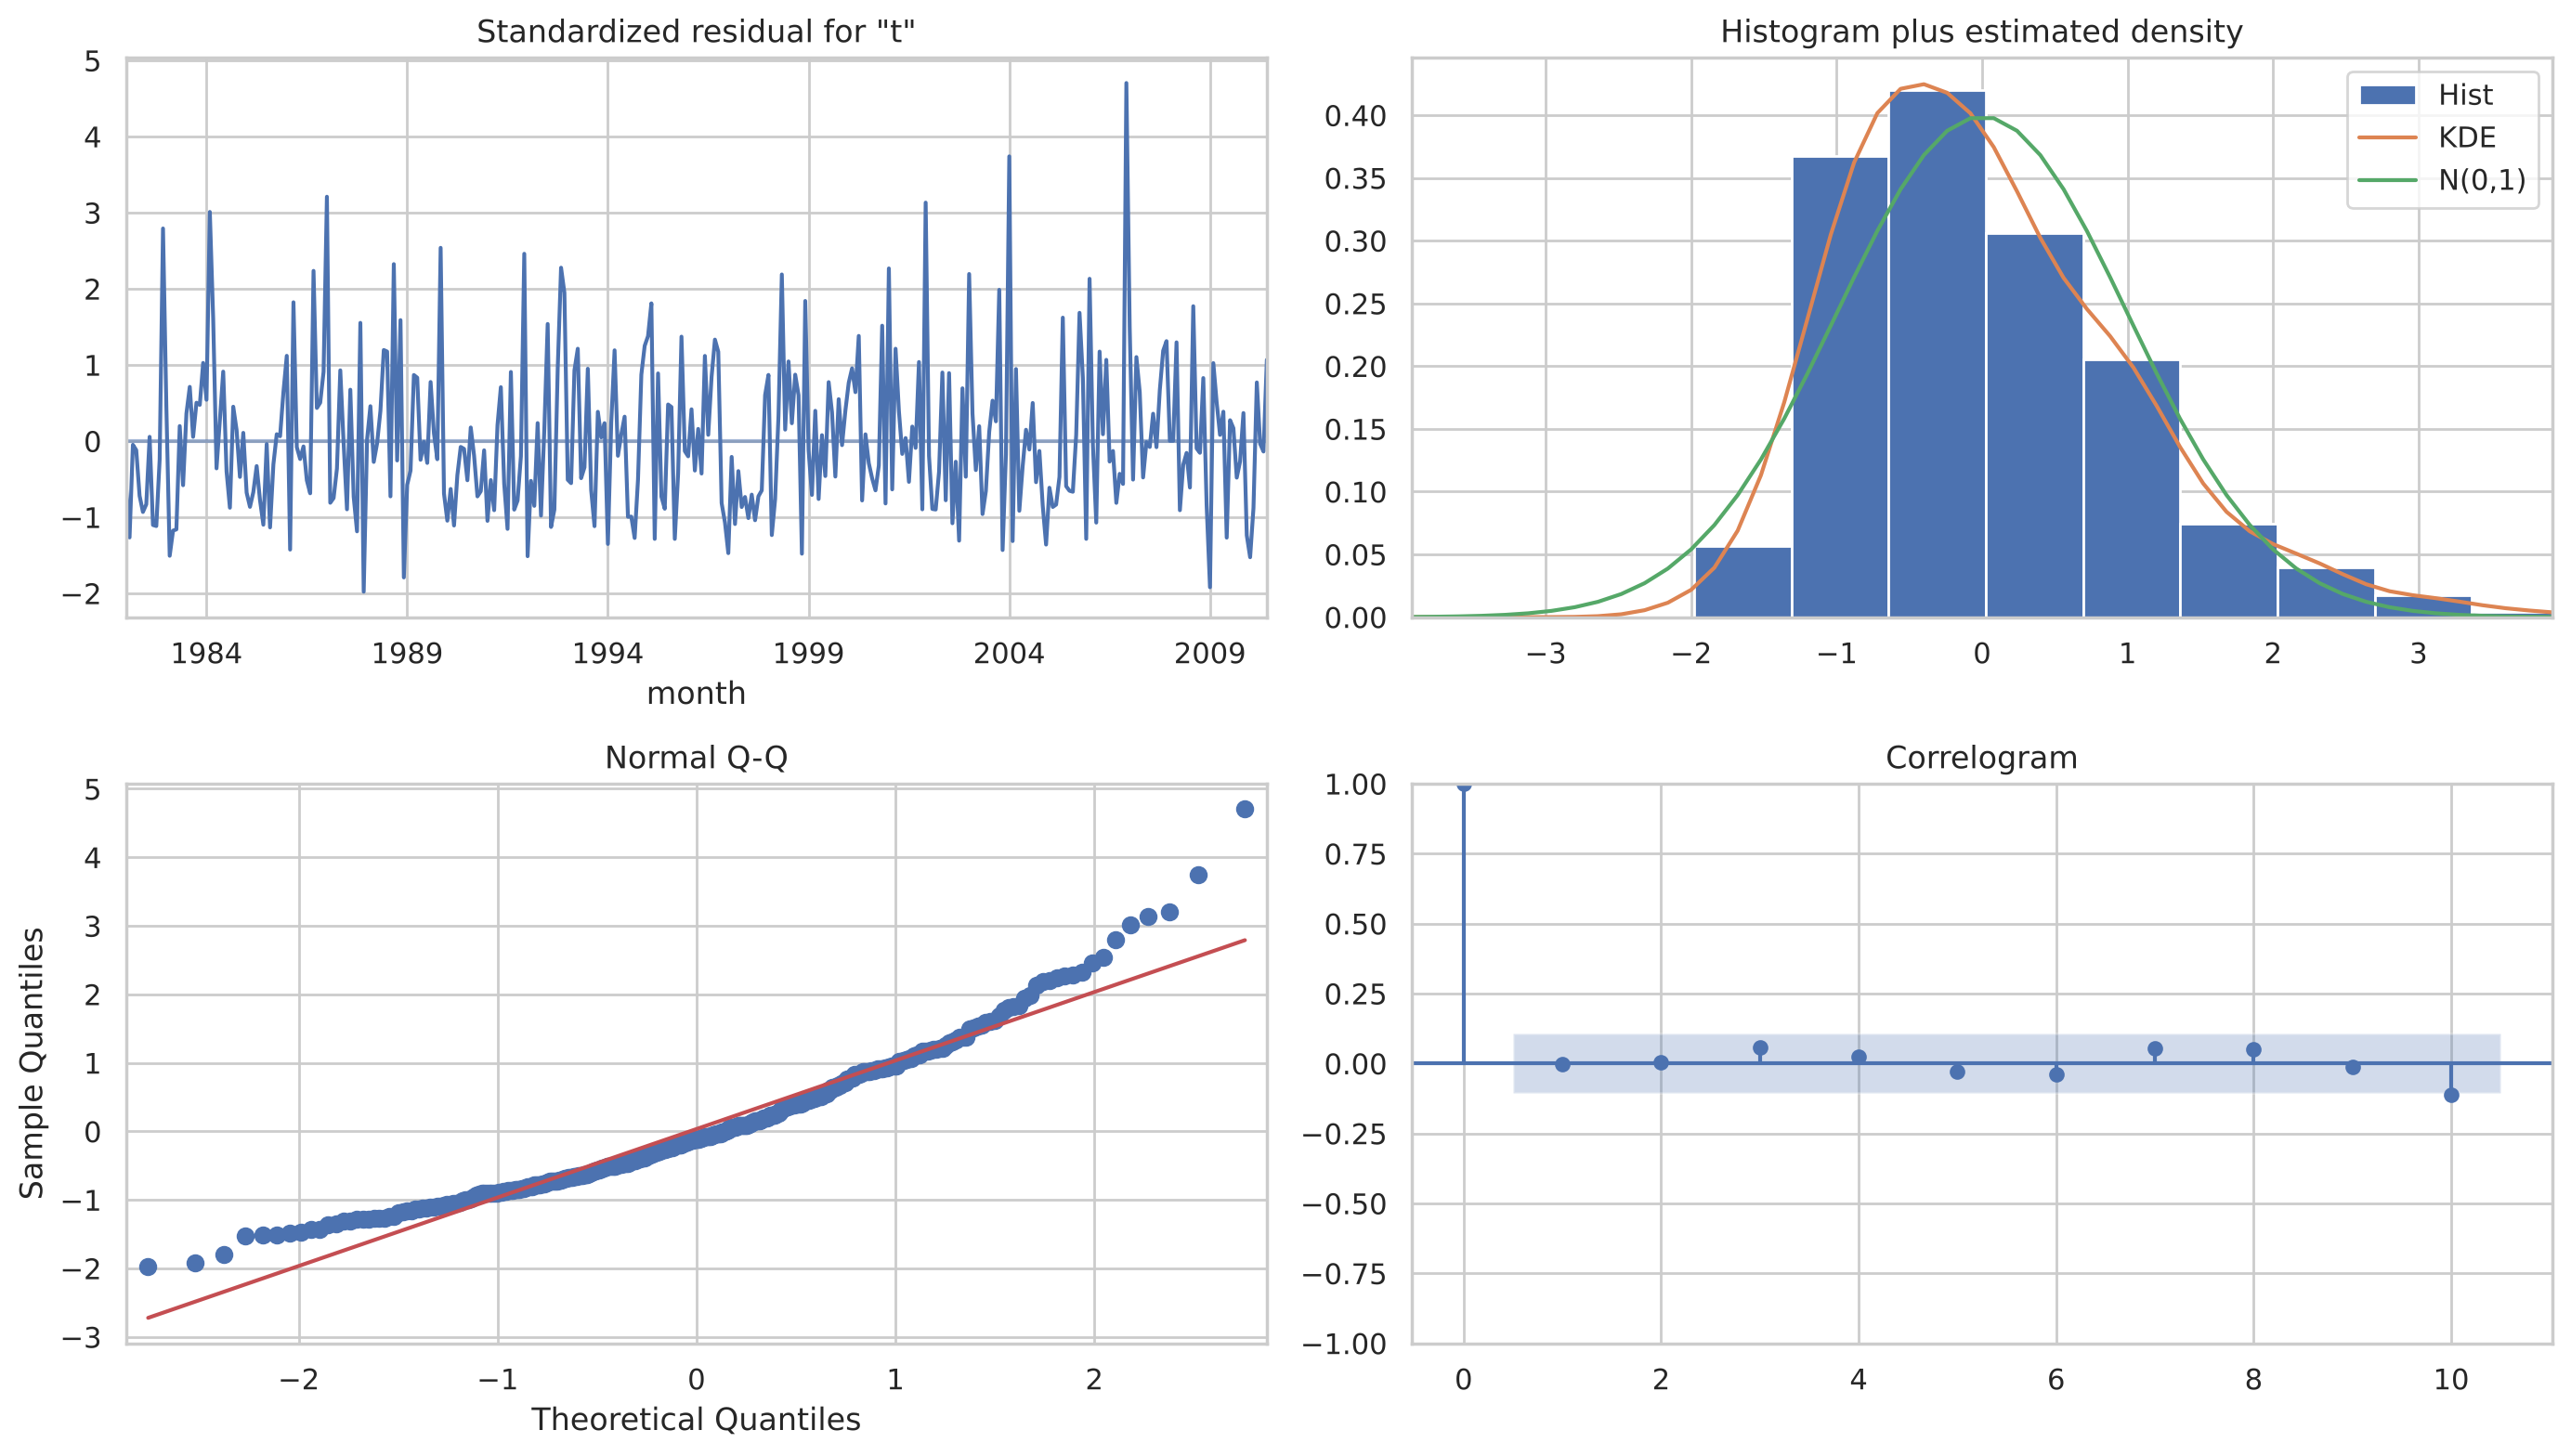

Ljung-Box test on residuals (H0: no remaining autocorrelation):
    lb_stat  lb_pvalue
12     9.10       0.69
24    29.62       0.20


In [21]:
# Residual diagnostics for the selected SARIMA on the total-rainfall series
order, sorder = RESULTS[TARGET_TOTAL]['SARIMA']['spec']
sarima_fit = fit_sarimax(selection_data[TARGET_TOTAL], order, sorder)
print(sarima_fit.summary().tables[1])
sarima_fit.plot_diagnostics(figsize=(14, 8)); plt.tight_layout(); plt.show()
lb = sm.stats.acorr_ljungbox(sarima_fit.resid.iloc[13:], lags=[12, 24], return_df=True)   # skip start-up residuals
print('Ljung-Box test on residuals (H0: no remaining autocorrelation):'); print(lb)

The Ljung-Box test checks whether the residuals still contain autocorrelation. Large p-values (here 0.69 at
lag 12 and 0.20 at lag 24) mean the model has captured the linear time structure.

Two caveats about the fitted models:
- The best ARIMA and the best AR are the same model, AR(1): with `d = 0` and AIC selection, no moving-average
  term improves on it, so their leaderboard rows are identical.
- In the SARIMA, the seasonal AR coefficient is close to 1 and is almost cancelled by the seasonal MA
  coefficient. The model is imitating a fixed seasonal profile using near-unit roots. That is a sign the
  seasonal pattern is better described by simple monthly averages, and the leaderboard agrees. The diagnostic plots also show heavy-tailed residuals
(the extreme months), which is why the Gaussian prediction intervals from ARIMA are not used for the final
forecast (see Section 14).

## 9. Feature engineering for machine learning models

Time series forecasting is turned into a supervised regression problem. Each row is a month *t*, and the
target is rainfall in month *t*.

**Leakage rule:** forecasts are made up to 12 months ahead, so every feature must use only information that is
**at least 12 months old**. With this rule a single model can forecast all 12 horizons directly, and the
backtest is an honest simulation of real use.

| Feature | Meaning |
|---|---|
| `month_sin`, `month_cos` | cyclical encoding of the calendar month (December is next to January) |
| `lag_12`, `lag_24`, `lag_36` | same month 1, 2 and 3 years earlier |
| `same_month_mean_3y` | mean of the three lags (smooths year-to-year noise) |
| `month_median_expanding` | median of all earlier years for this calendar month (climatology, no leakage) |
| `rolling_12m_mean_lag12` | average rainfall of the 12 months ending one year earlier (wet/dry year signal) |
| `rolling_12m_max_lag12` | wettest month in that 12-month window |

Targets are modelled as `log1p(rainfall)`; predictions are converted back with `expm1`.

In [22]:
def build_features(series):
    f = pd.DataFrame(index=series.index)
    month = series.index.month
    f['month_sin'] = np.sin(2 * np.pi * month / 12)
    f['month_cos'] = np.cos(2 * np.pi * month / 12)
    for k in (12, 24, 36):
        f[f'lag_{k}'] = series.shift(k)
    f['same_month_mean_3y'] = f[['lag_12', 'lag_24', 'lag_36']].mean(axis=1)
    f['month_median_expanding'] = series.groupby(month).transform(lambda x: x.shift(1).expanding().median())
    f['rolling_12m_mean_lag12'] = series.shift(12).rolling(12).mean()
    f['rolling_12m_max_lag12'] = series.shift(12).rolling(12).max()
    return f

def make_ml_forecaster(model_factory, log_target=True):
    """Train on the history, then forecast the next 12 months in one step (direct strategy)."""
    def forecast(train, return_model=False):
        extended = pd.concat([train, pd.Series(np.nan, index=future_index(train))])
        feats = build_features(extended)
        X_train, y_train = feats.iloc[:len(train)], train
        valid = X_train.notna().all(axis=1)
        X_train, y_train = X_train[valid], y_train[valid]
        model = model_factory()
        model.fit(X_train, np.log1p(y_train) if log_target else y_train)
        pred = model.predict(feats.iloc[len(train):])
        pred = np.expm1(pred) if log_target else pred
        pred = np.clip(pred, 0, None)
        return (pred, model, X_train.columns) if return_model else pred
    return forecast

build_features(df[TARGET_TOTAL]).dropna().head()

,month_sin,month_cos,lag_12,lag_24,lag_36,same_month_mean_3y,month_median_expanding,rolling_12m_mean_lag12,rolling_12m_max_lag12
month,,,,,,,,,
1985-01-01,0.50,0.87,251.20,246.00,107.10,201.43,246.00,166.58,370.60
1985-02-01,0.87,0.50,470.40,5.60,27.80,167.93,27.80,205.31,470.40
1985-03-01,1.00,0.00,361.30,18.60,160.80,180.23,160.80,233.87,470.40
1985-04-01,0.87,-0.50,153.10,33.60,157.00,114.57,153.10,243.82,470.40
1985-05-01,0.50,-0.87,186.50,160.80,102.20,149.83,160.80,245.97,470.40


## 10. Machine learning models: Linear Regression, Random Forest, XGBoost

- **Linear Regression** inside a `StandardScaler` pipeline.
- **Random Forest** (bagging of decision trees) with `min_samples_leaf=10` to avoid memorising noise.
- **XGBoost** (gradient boosting) with shallow trees (`max_depth=2`) and a low learning rate.

With only about 400 training rows and a weak signal, strong regularisation matters more than model
complexity. Hyperparameters are tuned only on the pre-2010 selection period (below).

In [23]:
# Small hyperparameter search for XGBoost on the selection period (1982 – Jun 2010),
# using an inner rolling-origin backtest (origins Jun 2004 – Jun 2009) so no backtest year is touched.
inner_origins = [pd.Timestamp(f'{y}-06-01') for y in range(2004, 2010)]
grid = [{'max_depth': d, 'n_estimators': n, 'learning_rate': lr}
        for d in (2, 3) for n in (200, 400) for lr in (0.02, 0.05)]
tuning = []
for params in grid:
    fn = make_ml_forecaster(lambda p=params: xgb.XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                                                              random_state=SEED, **p))
    mae = np.mean([evaluate(fn, selection_data[c], inner_origins)['MAE'] /
                   selection_data[c].mean() for c in [TARGET_TOTAL, TARGET_MAX]])
    tuning.append({**params, 'scaled MAE': mae})
tuning = pd.DataFrame(tuning).sort_values('scaled MAE').reset_index(drop=True)
best_xgb_params = tuning.iloc[0][['max_depth', 'n_estimators', 'learning_rate']].to_dict()
best_xgb_params = {'max_depth': int(best_xgb_params['max_depth']),
                   'n_estimators': int(best_xgb_params['n_estimators']),
                   'learning_rate': float(best_xgb_params['learning_rate'])}
print('Best XGBoost parameters:', best_xgb_params)
tuning.head()

Best XGBoost parameters: {'max_depth': 2, 'n_estimators': 200, 'learning_rate': 0.02}


,max_depth,n_estimators,learning_rate,scaled MAE
0,2,200,0.02,0.45
1,3,200,0.02,0.45
2,2,400,0.02,0.46
3,2,200,0.05,0.47
4,3,400,0.02,0.47


In [24]:
ML_MODELS = {
    'Linear Regression': lambda: make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=10,
                                                   max_features=0.6, random_state=SEED, n_jobs=-1),
    'XGBoost': lambda: xgb.XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                                        random_state=SEED, **best_xgb_params),
}
for name, factory in ML_MODELS.items():
    print(name); print(run_model(name, make_ml_forecaster(factory)).round(1), '\n')

Linear Regression


                            MAE  RMSE
total_rainfall            64.80 85.00
maximum_rainfall_in_a_day 19.40 28.20 

Random Forest


                            MAE  RMSE
total_rainfall            64.60 86.70
maximum_rainfall_in_a_day 18.90 27.70 

XGBoost


                            MAE  RMSE
total_rainfall            64.60 85.20
maximum_rainfall_in_a_day 19.00 27.90 



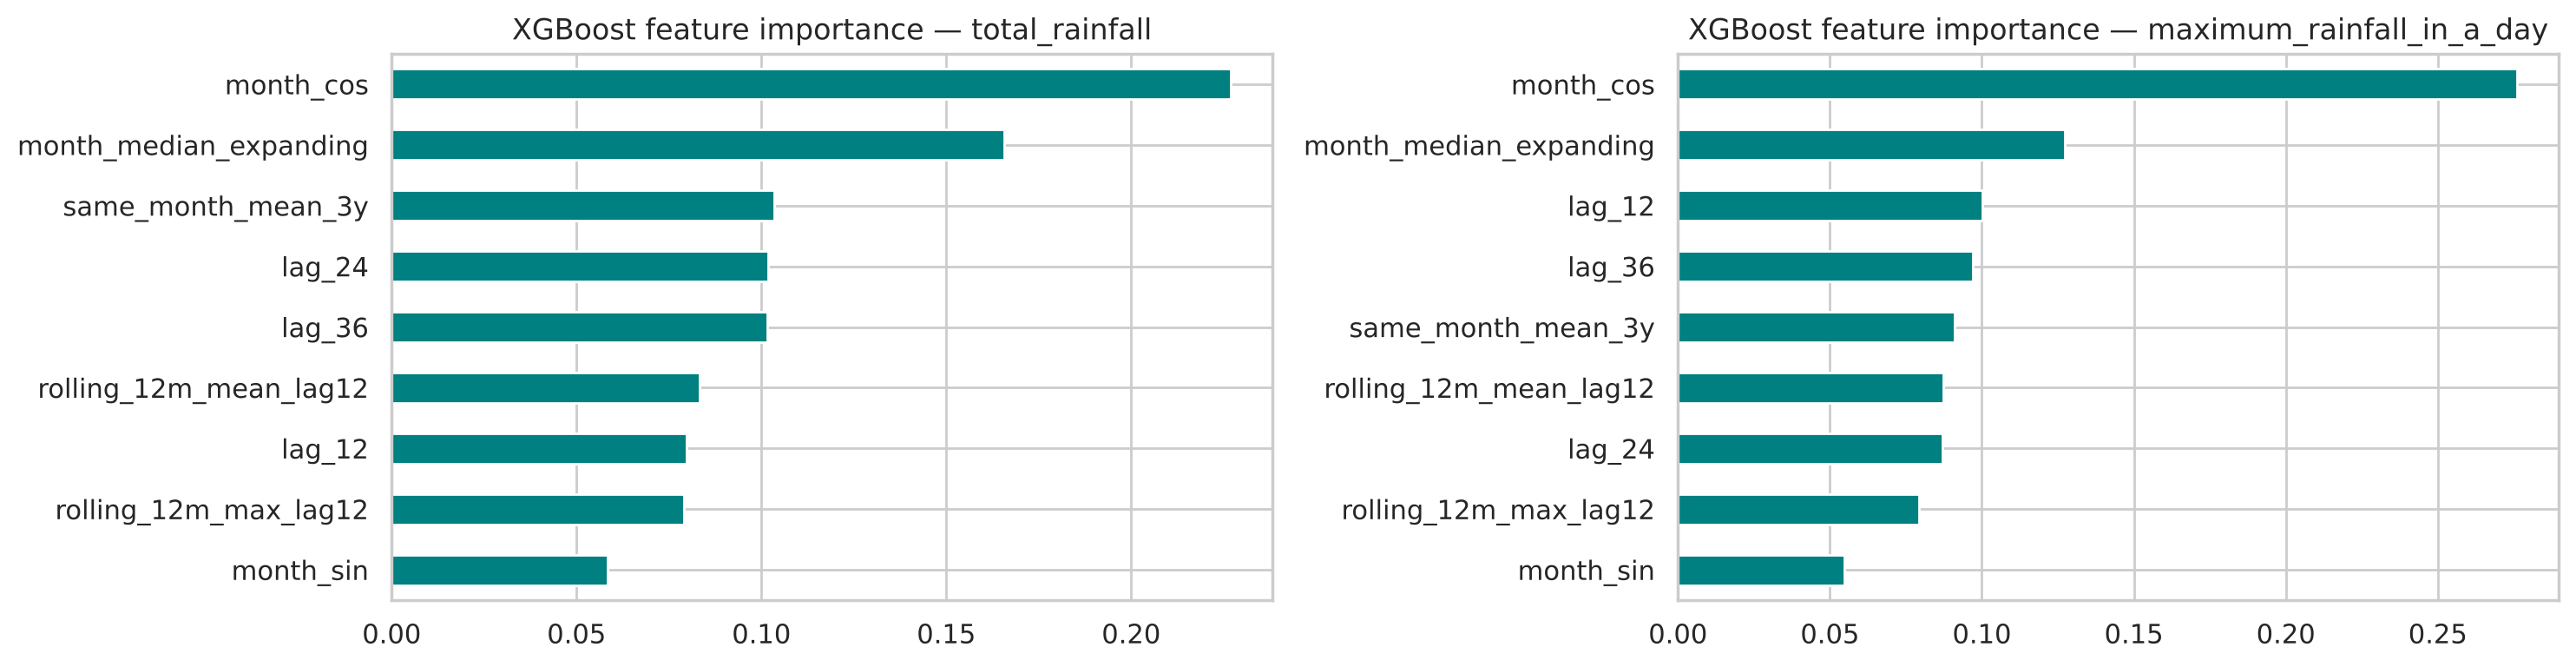

In [25]:
# Which features drive the models? (fitted on the full selection period)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    _, model, cols = make_ml_forecaster(ML_MODELS['XGBoost'])(df[col][:BACKTEST_ORIGINS[0]], return_model=True)
    pd.Series(model.feature_importances_, index=cols).sort_values().plot.barh(ax=ax, color='teal')
    ax.set_title(f'XGBoost feature importance — {col}')
plt.tight_layout(); plt.show()

## 11. Deep learning: LSTM (Keras / TensorFlow)

An LSTM reads the previous 36 months (log-transformed and standardised, plus the calendar month encoding) and
outputs all 12 future months at once (multi-output, direct strategy). Early stopping on the most recent 15% of
training windows limits overfitting.

With only about 400 training windows, deep learning is not expected to beat simpler models here; it is
included to test that expectation rather than assume it.

In [26]:
import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel('ERROR')

LOOKBACK = 36

def make_windows(values, months, lookback=LOOKBACK, h=H):
    X, y = [], []
    for i in range(lookback, len(values) - h + 1):
        X.append(np.column_stack([values[i - lookback:i],
                                  np.sin(2 * np.pi * months[i - lookback:i] / 12),
                                  np.cos(2 * np.pi * months[i - lookback:i] / 12)]))
        y.append(values[i:i + h])
    return np.array(X), np.array(y)

def lstm_forecast(train):
    keras.utils.set_random_seed(SEED)
    logv = np.log1p(train.values)
    mu, sd = logv.mean(), logv.std()
    z = (logv - mu) / sd
    months = train.index.month.values
    X, y = make_windows(z, months)
    model = keras.Sequential([
        keras.layers.Input(shape=(LOOKBACK, 3)),
        keras.layers.LSTM(32),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(H),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mae')
    model.fit(X, y, epochs=200, batch_size=32, validation_split=0.15, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
    x_last = np.column_stack([z[-LOOKBACK:], np.sin(2 * np.pi * months[-LOOKBACK:] / 12),
                              np.cos(2 * np.pi * months[-LOOKBACK:] / 12)])[None, ...]
    pred = model.predict(x_last, verbose=0)[0]
    return np.clip(np.expm1(pred * sd + mu), 0, None)

print(run_model('LSTM', lstm_forecast).round(1))

I0000 00:00:1795008169.325030     239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795008186.260569     239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


                            MAE  RMSE
total_rainfall            74.20 92.70
maximum_rainfall_in_a_day 19.50 28.40


## 12. Forecast combination (ensemble)

No single model dominates (see the leaderboard below), and their forecasts are very similar. Averaging
several reasonable forecasts is a standard way to reduce variance when individual models are noisy.

**Ensemble = simple average of: Monthly median, Linear Regression, Random Forest, XGBoost.**
It is chosen as the final model **by design, not by ranking**: with differences this small, picking whichever
model happens to be first on a noisy leaderboard would be choosing noise. SARIMA, ARIMA, AR, MA, Holt-Winters
and the LSTM are left out because they are consistently no better than the climatology baseline and are
heavier to serve. The four members are light, need no GPU, and can all be served from the same feature set.

In [27]:
ENSEMBLE_MEMBERS = ['Monthly median', 'Linear Regression', 'Random Forest', 'XGBoost']

def make_ensemble_forecaster(col):
    fns = [RESULTS[col][m]['fn'] for m in ENSEMBLE_MEMBERS]
    return lambda train: np.mean([f(train) for f in fns], axis=0)

for col in [TARGET_TOTAL, TARGET_MAX]:
    member_preds = [RESULTS[col][m]['backtest']['preds'] for m in ENSEMBLE_MEMBERS]
    preds = member_preds[0][['actual']].copy()
    preds['pred'] = np.mean([mp['pred'].values for mp in member_preds], axis=0)   # same 108 months for every member
    err = preds['actual'] - preds['pred']
    fold_mae = [np.abs(err.iloc[i:i + H]).mean() for i in range(0, len(err), H)]
    RESULTS[col]['Ensemble'] = {'fn': make_ensemble_forecaster(col),
                                'backtest': {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean()),
                                             'fold_MAE_std': np.std(fold_mae), 'preds': preds}}
    print(f"{col}: Ensemble backtest MAE = {np.abs(err).mean():.1f}, RMSE = {np.sqrt((err ** 2).mean()):.1f}")

total_rainfall: Ensemble backtest MAE = 63.7, RMSE = 83.8
maximum_rainfall_in_a_day: Ensemble backtest MAE = 19.0, RMSE = 27.8


## 13. Model comparison (backtest, 108 out-of-sample months)

### 13.1 Task 1 — monthly total rainfall

In [28]:
lb_total = leaderboard(TARGET_TOTAL)
lb_total.style.format({'MAE': '{:.1f}', 'RMSE': '{:.1f}', 'fold MAE std': '{:.1f}', 'skill vs naive': '{:+.1%}'}) \
    .background_gradient(subset=['MAE'], cmap='RdYlGn_r')

,model,MAE,RMSE,fold MAE std,skill vs naive
0,Ensemble,63.7,83.8,16.1,+26.1%
1,Monthly median,63.9,83.2,14.8,+25.9%
2,XGBoost,64.6,85.2,15.1,+25.1%
3,Random Forest,64.6,86.7,17.2,+25.1%
4,Linear Regression,64.8,85.0,17.3,+24.8%
5,Holt-Winters,67.3,85.5,15.2,+22.0%
6,Monthly mean,67.3,85.5,15.2,+22.0%
7,SARIMA,68.9,87.3,17.3,+20.2%
8,LSTM,74.2,92.7,15.0,+14.0%
9,ARIMA,78.7,96.4,17.6,+8.7%


### 13.2 Task 2 — highest daily rainfall in the month

In [29]:
lb_max = leaderboard(TARGET_MAX)
lb_max.style.format({'MAE': '{:.1f}', 'RMSE': '{:.1f}', 'fold MAE std': '{:.1f}', 'skill vs naive': '{:+.1%}'}) \
    .background_gradient(subset=['MAE'], cmap='RdYlGn_r')

,model,MAE,RMSE,fold MAE std,skill vs naive
0,Random Forest,18.9,27.7,7.5,+34.2%
1,Ensemble,19.0,27.8,7.7,+33.9%
2,XGBoost,19.0,27.9,7.6,+33.8%
3,Monthly median,19.3,28.3,7.6,+32.9%
4,Linear Regression,19.4,28.2,7.7,+32.6%
5,LSTM,19.5,28.4,7.1,+32.2%
6,SARIMA,21.8,29.1,6.2,+24.3%
7,Holt-Winters,22.4,30.2,6.0,+22.0%
8,Monthly mean,22.4,30.2,6.0,+22.0%
9,ARIMA,23.0,30.4,5.1,+20.0%


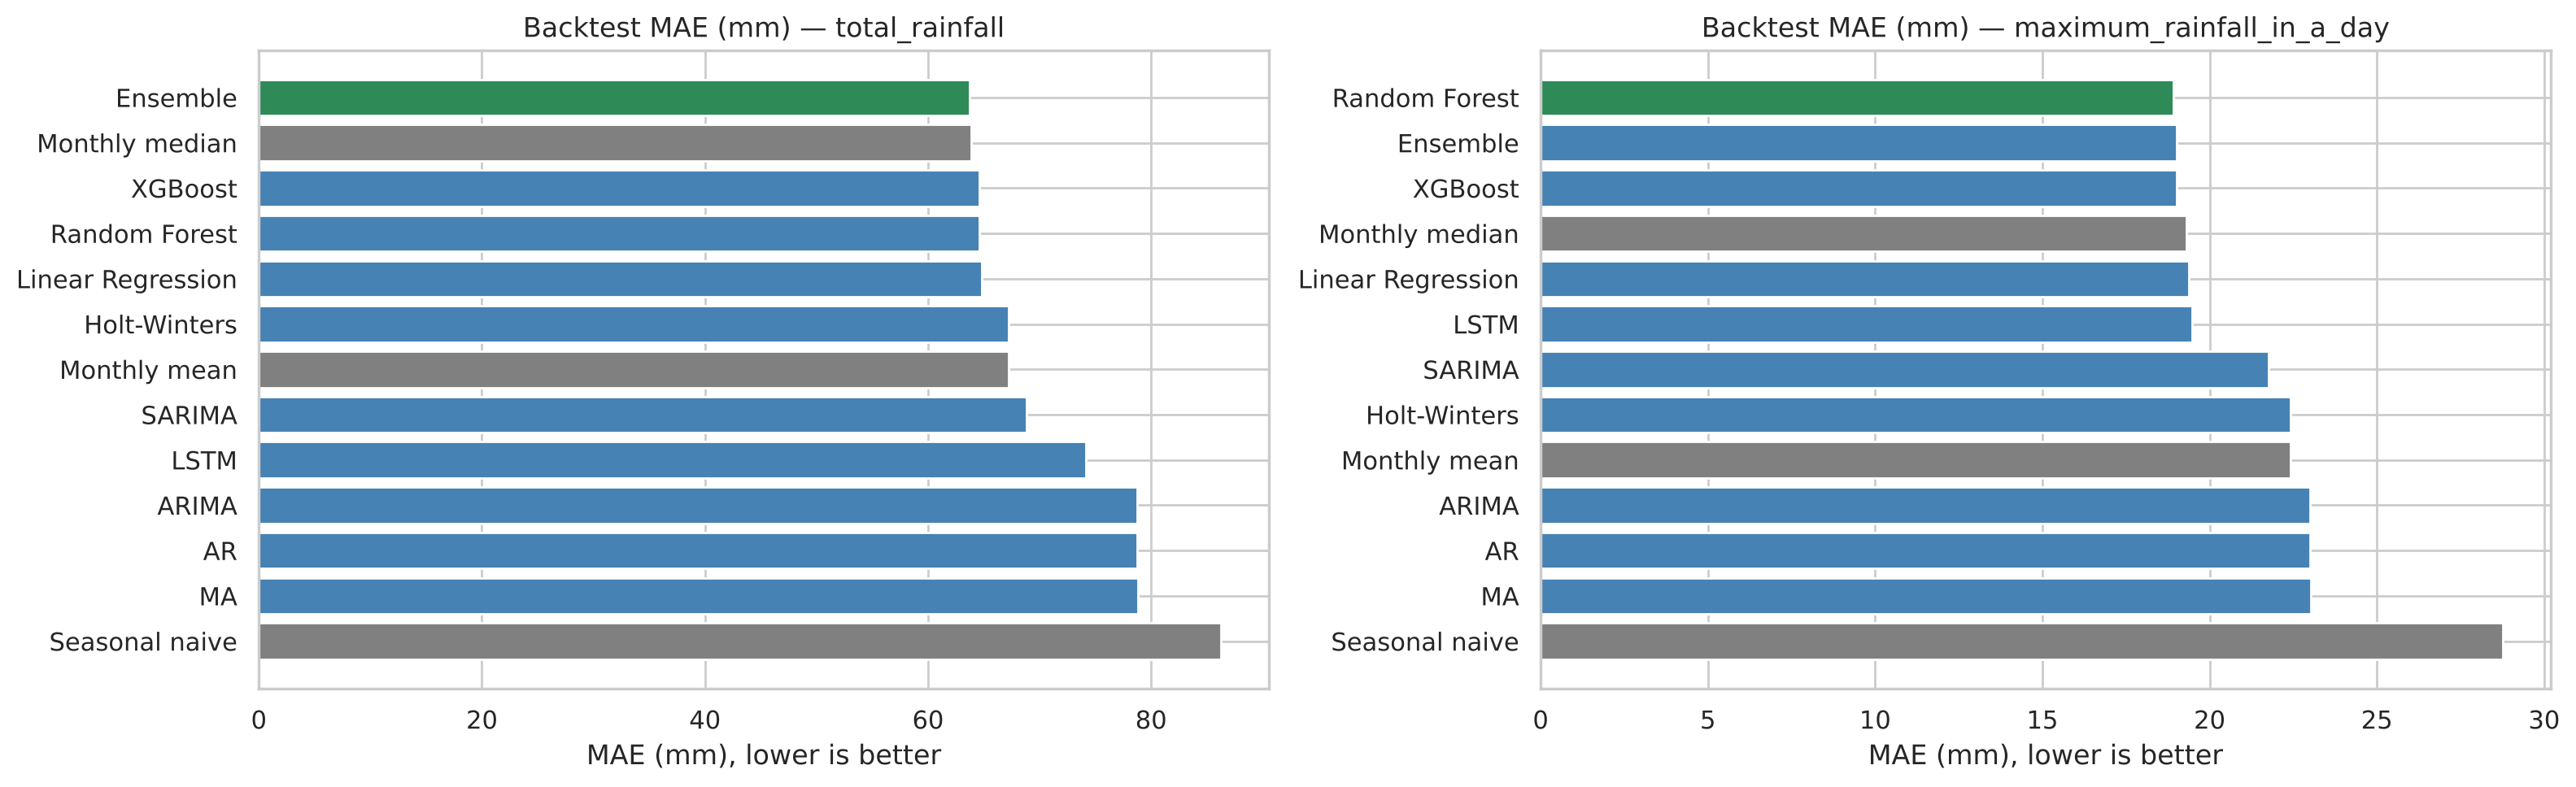

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (col, lb) in zip(axes, [(TARGET_TOTAL, lb_total), (TARGET_MAX, lb_max)]):
    colors = ['seagreen' if i == 0 else ('grey' if m in ('Seasonal naive', 'Monthly mean', 'Monthly median')
              else 'steelblue') for i, m in enumerate(lb['model'])]
    ax.barh(lb['model'][::-1], lb['MAE'][::-1], color=colors[::-1])
    ax.set_title(f'Backtest MAE (mm) — {col}'); ax.set_xlabel('MAE (mm), lower is better')
plt.tight_layout(); plt.show()

In [31]:
# Is any model's advantage over the monthly-median baseline real or noise?
# Paired comparison of absolute errors on the same 108 months (Wilcoxon signed-rank test).
rows = []
for col in [TARGET_TOTAL, TARGET_MAX]:
    e_base = (RESULTS[col]['Monthly median']['backtest']['preds'].eval('actual - pred')).abs()
    for name in RESULTS[col]:
        if name == 'Monthly median':
            continue
        e = (RESULTS[col][name]['backtest']['preds'].eval('actual - pred')).abs()
        p = stats.wilcoxon(e, e_base).pvalue
        rows.append({'target': col, 'model': name, 'MAE': e.mean(), 'MAE diff vs median (mm)': e.mean() - e_base.mean(),
                     'Wilcoxon p': p, 'significant at 5%': p < 0.05})
sig = pd.DataFrame(rows).sort_values(['target', 'MAE'])
print('Negative difference = better than the monthly median.')
sig.round(3)

Negative difference = better than the monthly median.


,target,model,MAE,MAE diff vs median (mm),Wilcoxon p,significant at 5%
20,maximum_rainfall_in_a_day,Random Forest,18.91,-0.39,0.54,False
23,maximum_rainfall_in_a_day,Ensemble,19.01,-0.29,0.55,False
21,maximum_rainfall_in_a_day,XGBoost,19.02,-0.27,0.66,False
19,maximum_rainfall_in_a_day,Linear Regression,19.37,0.08,0.64,False
22,maximum_rainfall_in_a_day,LSTM,19.48,0.19,0.60,False
17,maximum_rainfall_in_a_day,SARIMA,21.75,2.46,0.00,True
18,maximum_rainfall_in_a_day,Holt-Winters,22.42,3.13,0.00,True
13,maximum_rainfall_in_a_day,Monthly mean,22.42,3.13,0.00,True
14,maximum_rainfall_in_a_day,AR,23.01,3.71,0.01,True
16,maximum_rainfall_in_a_day,ARIMA,23.01,3.71,0.01,True


## 14. Prediction intervals with XGBoost quantile regression

A single number hides how uncertain a 12-month rainfall forecast is. XGBoost is trained with the quantile
(pinball) loss at the 10th, 50th and 90th percentiles, giving an **80% prediction interval**. Quantiles are
unaffected by the monotonic `log1p` transform, so the same features and target transform are reused.

A good interval should contain the actual value about 80% of the time in the backtest (**coverage**).

In [32]:
def make_quantile_forecaster(alpha):
    return make_ml_forecaster(lambda: xgb.XGBRegressor(objective='reg:quantileerror', quantile_alpha=alpha,
                                                       subsample=0.8, colsample_bytree=0.8,
                                                       random_state=SEED, **best_xgb_params))

QUANTILES = {'q10': 0.10, 'q50': 0.50, 'q90': 0.90}
interval_bt = {}
for col in [TARGET_TOTAL, TARGET_MAX]:
    parts = {k: evaluate(make_quantile_forecaster(a), df[col], BACKTEST_ORIGINS)['preds']
             for k, a in QUANTILES.items()}
    out = parts['q50'].rename(columns={'pred': 'q50'})
    out['q10'], out['q90'] = parts['q10']['pred'], parts['q90']['pred']
    interval_bt[col] = out
    coverage = ((out.actual >= out.q10) & (out.actual <= out.q90)).mean()
    width = (out.q90 - out.q10).mean()
    print(f'{col}: 80% interval coverage = {coverage:.0%}, average width = {width:.0f} mm, '
          f'median-forecast MAE = {(out.actual - out.q50).abs().mean():.1f}')

total_rainfall: 80% interval coverage = 85%, average width = 255 mm, median-forecast MAE = 70.1


maximum_rainfall_in_a_day: 80% interval coverage = 80%, average width = 70 mm, median-forecast MAE = 19.3


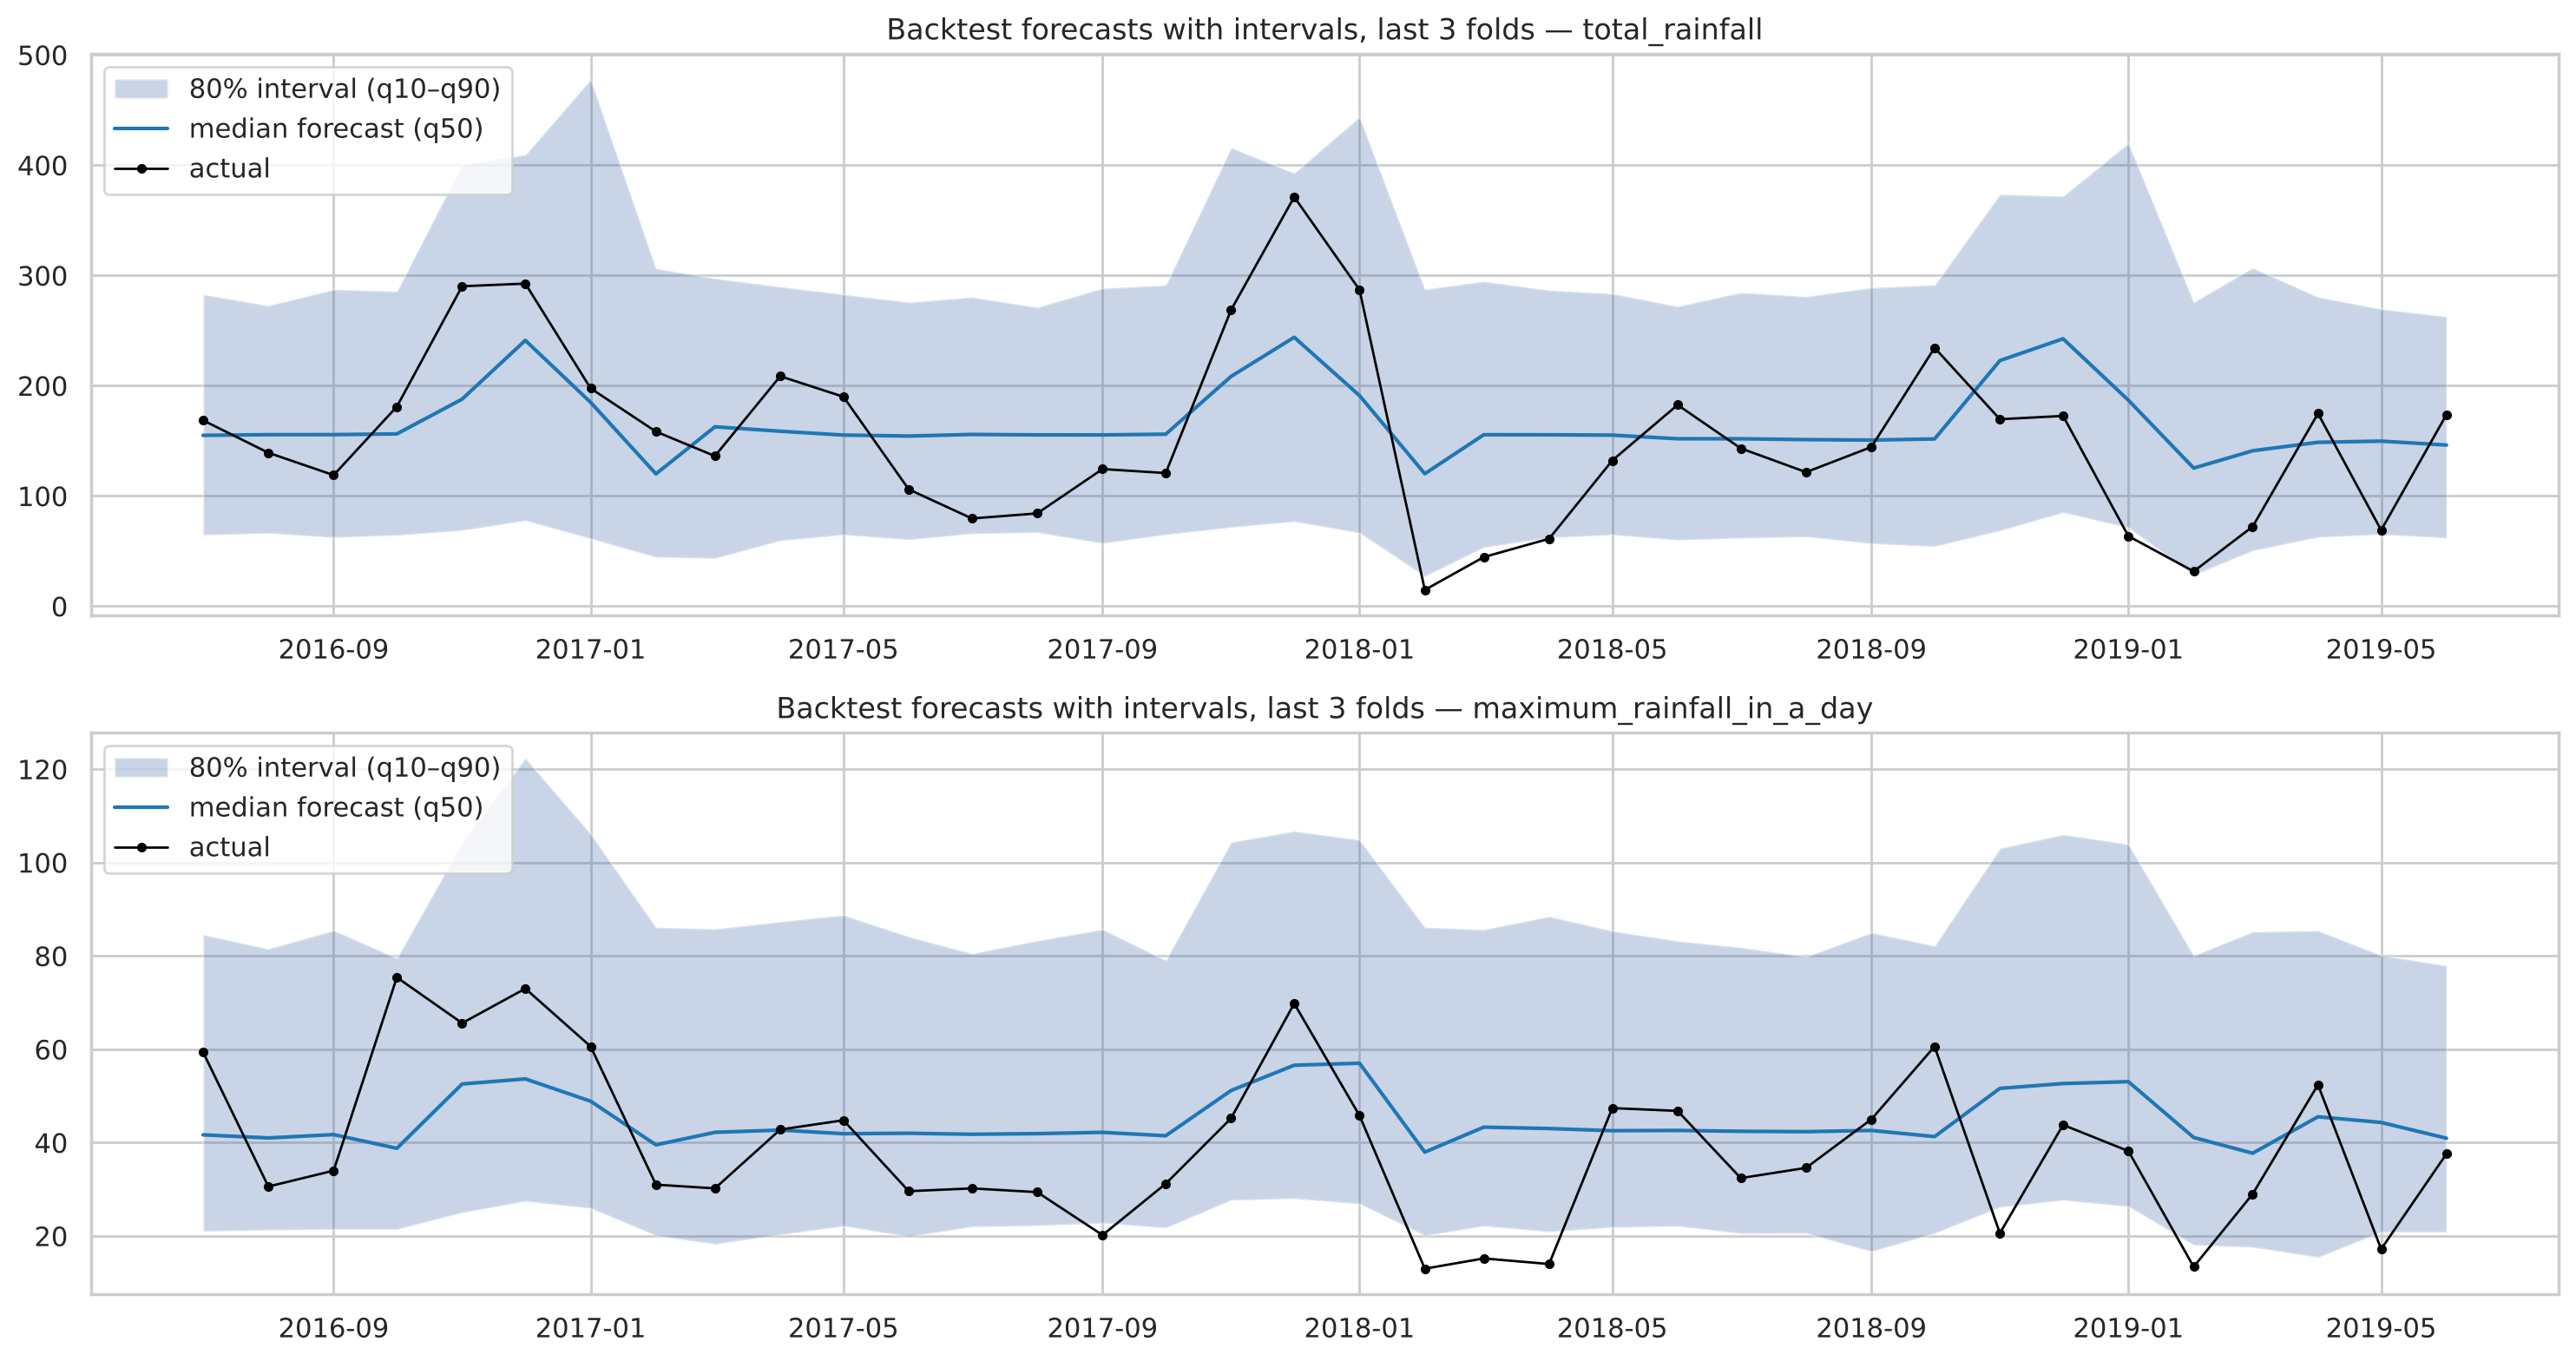

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    out = interval_bt[col].iloc[-36:]
    ax.fill_between(out.index, out.q10, out.q90, alpha=0.3, label='80% interval (q10–q90)')
    ax.plot(out.index, out.q50, color='tab:blue', label='median forecast (q50)')
    ax.plot(out.index, out.actual, 'o-', color='black', ms=3, lw=1, label='actual')
    ax.set_title(f'Backtest forecasts with intervals, last 3 folds — {col}'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## 15. Holdout year check (Jul 2019 – Jun 2020)

The holdout year is **not used to fit, tune or rank any model**. The ensemble (final model by design) is
evaluated on it alongside the baselines and the best single model from the backtest, as a sanity check.

In [34]:
best_single = {col: [m for m in leaderboard(col)['model'] if m not in ('Ensemble',)][0] for col in [TARGET_TOTAL, TARGET_MAX]}
best_model = {TARGET_TOTAL: 'Ensemble', TARGET_MAX: 'Ensemble'}
holdout_rows, holdout_preds = [], {}
for col in [TARGET_TOTAL, TARGET_MAX]:
    names = list(dict.fromkeys(['Ensemble', 'Monthly median', best_single[col], 'Seasonal naive']))
    for name in names:
        r = evaluate(RESULTS[col][name]['fn'], df[col], [HOLDOUT_ORIGIN])
        holdout_rows.append({'target': col, 'model': name, 'holdout MAE': r['MAE'], 'holdout RMSE': r['RMSE']})
        holdout_preds[(col, name)] = r['preds']
holdout_table = pd.DataFrame(holdout_rows)
print('Final model:', best_model, '| best single model in backtest:', best_single)
holdout_table.round(1)

Final model: {'total_rainfall': 'Ensemble', 'maximum_rainfall_in_a_day': 'Ensemble'} | best single model in backtest: {'total_rainfall': 'Monthly median', 'maximum_rainfall_in_a_day': 'Random Forest'}


,target,model,holdout MAE,holdout RMSE
0,total_rainfall,Ensemble,86.80,96.80
1,total_rainfall,Monthly median,84.90,97.00
2,total_rainfall,Seasonal naive,88.00,112.50
3,maximum_rainfall_in_a_day,Ensemble,19.90,24.30
4,maximum_rainfall_in_a_day,Monthly median,17.20,23.00
5,maximum_rainfall_in_a_day,Random Forest,21.80,26.30
6,maximum_rainfall_in_a_day,Seasonal naive,22.50,27.30


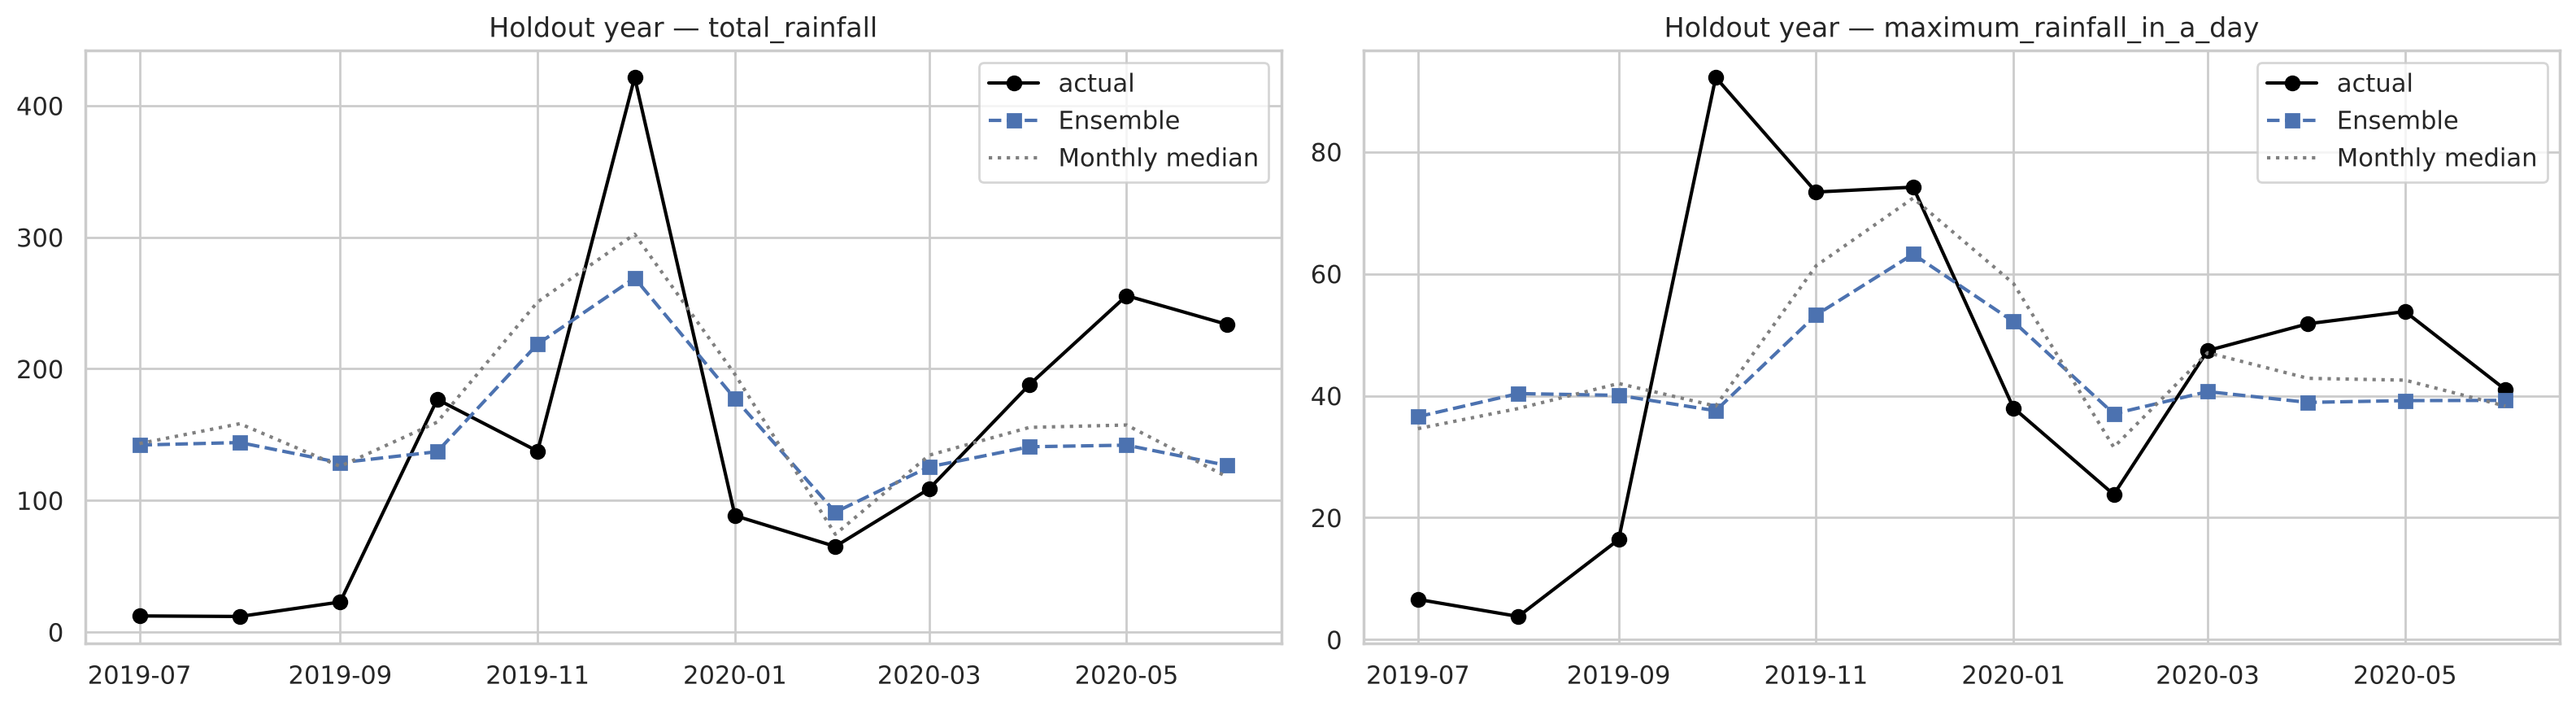

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    p = holdout_preds[(col, 'Ensemble')]
    ax.plot(p.index, p.actual, 'o-', color='black', label='actual')
    ax.plot(p.index, p.pred, 's--', label='Ensemble')
    ax.plot(p.index, holdout_preds[(col, 'Monthly median')].pred, ':', color='grey', label='Monthly median')
    ax.set_title(f'Holdout year — {col}'); ax.legend()
plt.tight_layout(); plt.show()

One holdout year is only 12 points, so its MAE is noisy; the 108-month backtest is the more reliable
estimate of future accuracy. The holdout only confirms that the ensemble behaves sensibly on the most recent data.

## 16. Final forecast: July 2020 – June 2021

The ensemble for each target is retrained on **all** data (January 1982 – June 2020) and forecasts the
next 12 months. The 80% interval comes from the XGBoost quantile models, also retrained on all data (the point forecast is the
ensemble average; the interval is not centred on it).

In [36]:
final_forecasts = {}
for col in [TARGET_TOTAL, TARGET_MAX]:
    series = df[col]
    idx = future_index(series)
    point = RESULTS[col][best_model[col]]['fn'](series)
    fc = pd.DataFrame({'forecast': point,
                       'lower_80': make_quantile_forecaster(0.10)(series),
                       'upper_80': make_quantile_forecaster(0.90)(series)}, index=idx)
    fc['lower_80'] = np.minimum(fc['lower_80'], fc['forecast'])
    fc['upper_80'] = np.maximum(fc['upper_80'], fc['forecast'])
    final_forecasts[col] = fc

forecast_table = pd.concat({'Total rainfall (mm)': final_forecasts[TARGET_TOTAL],
                            'Highest daily rainfall (mm)': final_forecasts[TARGET_MAX]}, axis=1)
forecast_table.index = forecast_table.index.strftime('%Y-%m')
print(f"Forecast total rainfall Jul 2020 – Jun 2021: {final_forecasts[TARGET_TOTAL]['forecast'].sum():,.0f} mm "
      f"(1982–2019 annual mean: {annual[TARGET_TOTAL].mean():,.0f} mm)")
forecast_table.round(1)

Forecast total rainfall Jul 2020 – Jun 2021: 1,875 mm (1982–2019 annual mean: 2,118 mm)


Total rainfall (mm)                   Highest daily rainfall (mm)  \
                   forecast lower_80 upper_80                    forecast   
2020-07              134.20    56.10   281.90                       35.50   
2020-08              140.00    50.30   281.90                       37.70   
2020-09              139.20    59.80   281.00                       39.90   
2020-10              148.60    67.10   277.30                       36.20   
2020-11              219.60    70.00   412.90                       53.00   
2020-12              299.20    83.10   434.60                       63.60   
2021-01              175.50    62.60   433.90                       51.90   
2021-02               94.70    50.10   320.80                       34.40   
2021-03              117.60    56.90   285.00                       38.20   
2021-04              140.90    61.10   276.10                       35.70   
2021-05              144.40    60.80   274.40                       39.00   
2021-06              120.70    61.60   255.50                       37.60   

                           
        lower_80 upper_80  
2020-07    18.30    79.90  
2020-08    18.30    80.90  
2020-09    15.80    82.20  
2020-10    20.60    78.10  
2020-11    25.00   102.50  
2020-12    26.90    98.90  
2021-01    20.80    96.40  
2021-02    18.50    83.20  
2021-03    17.70    81.50  
2021-04    17.60    81.30  
2021-05    19.10    80.00  
2021-06    19.00    80.60

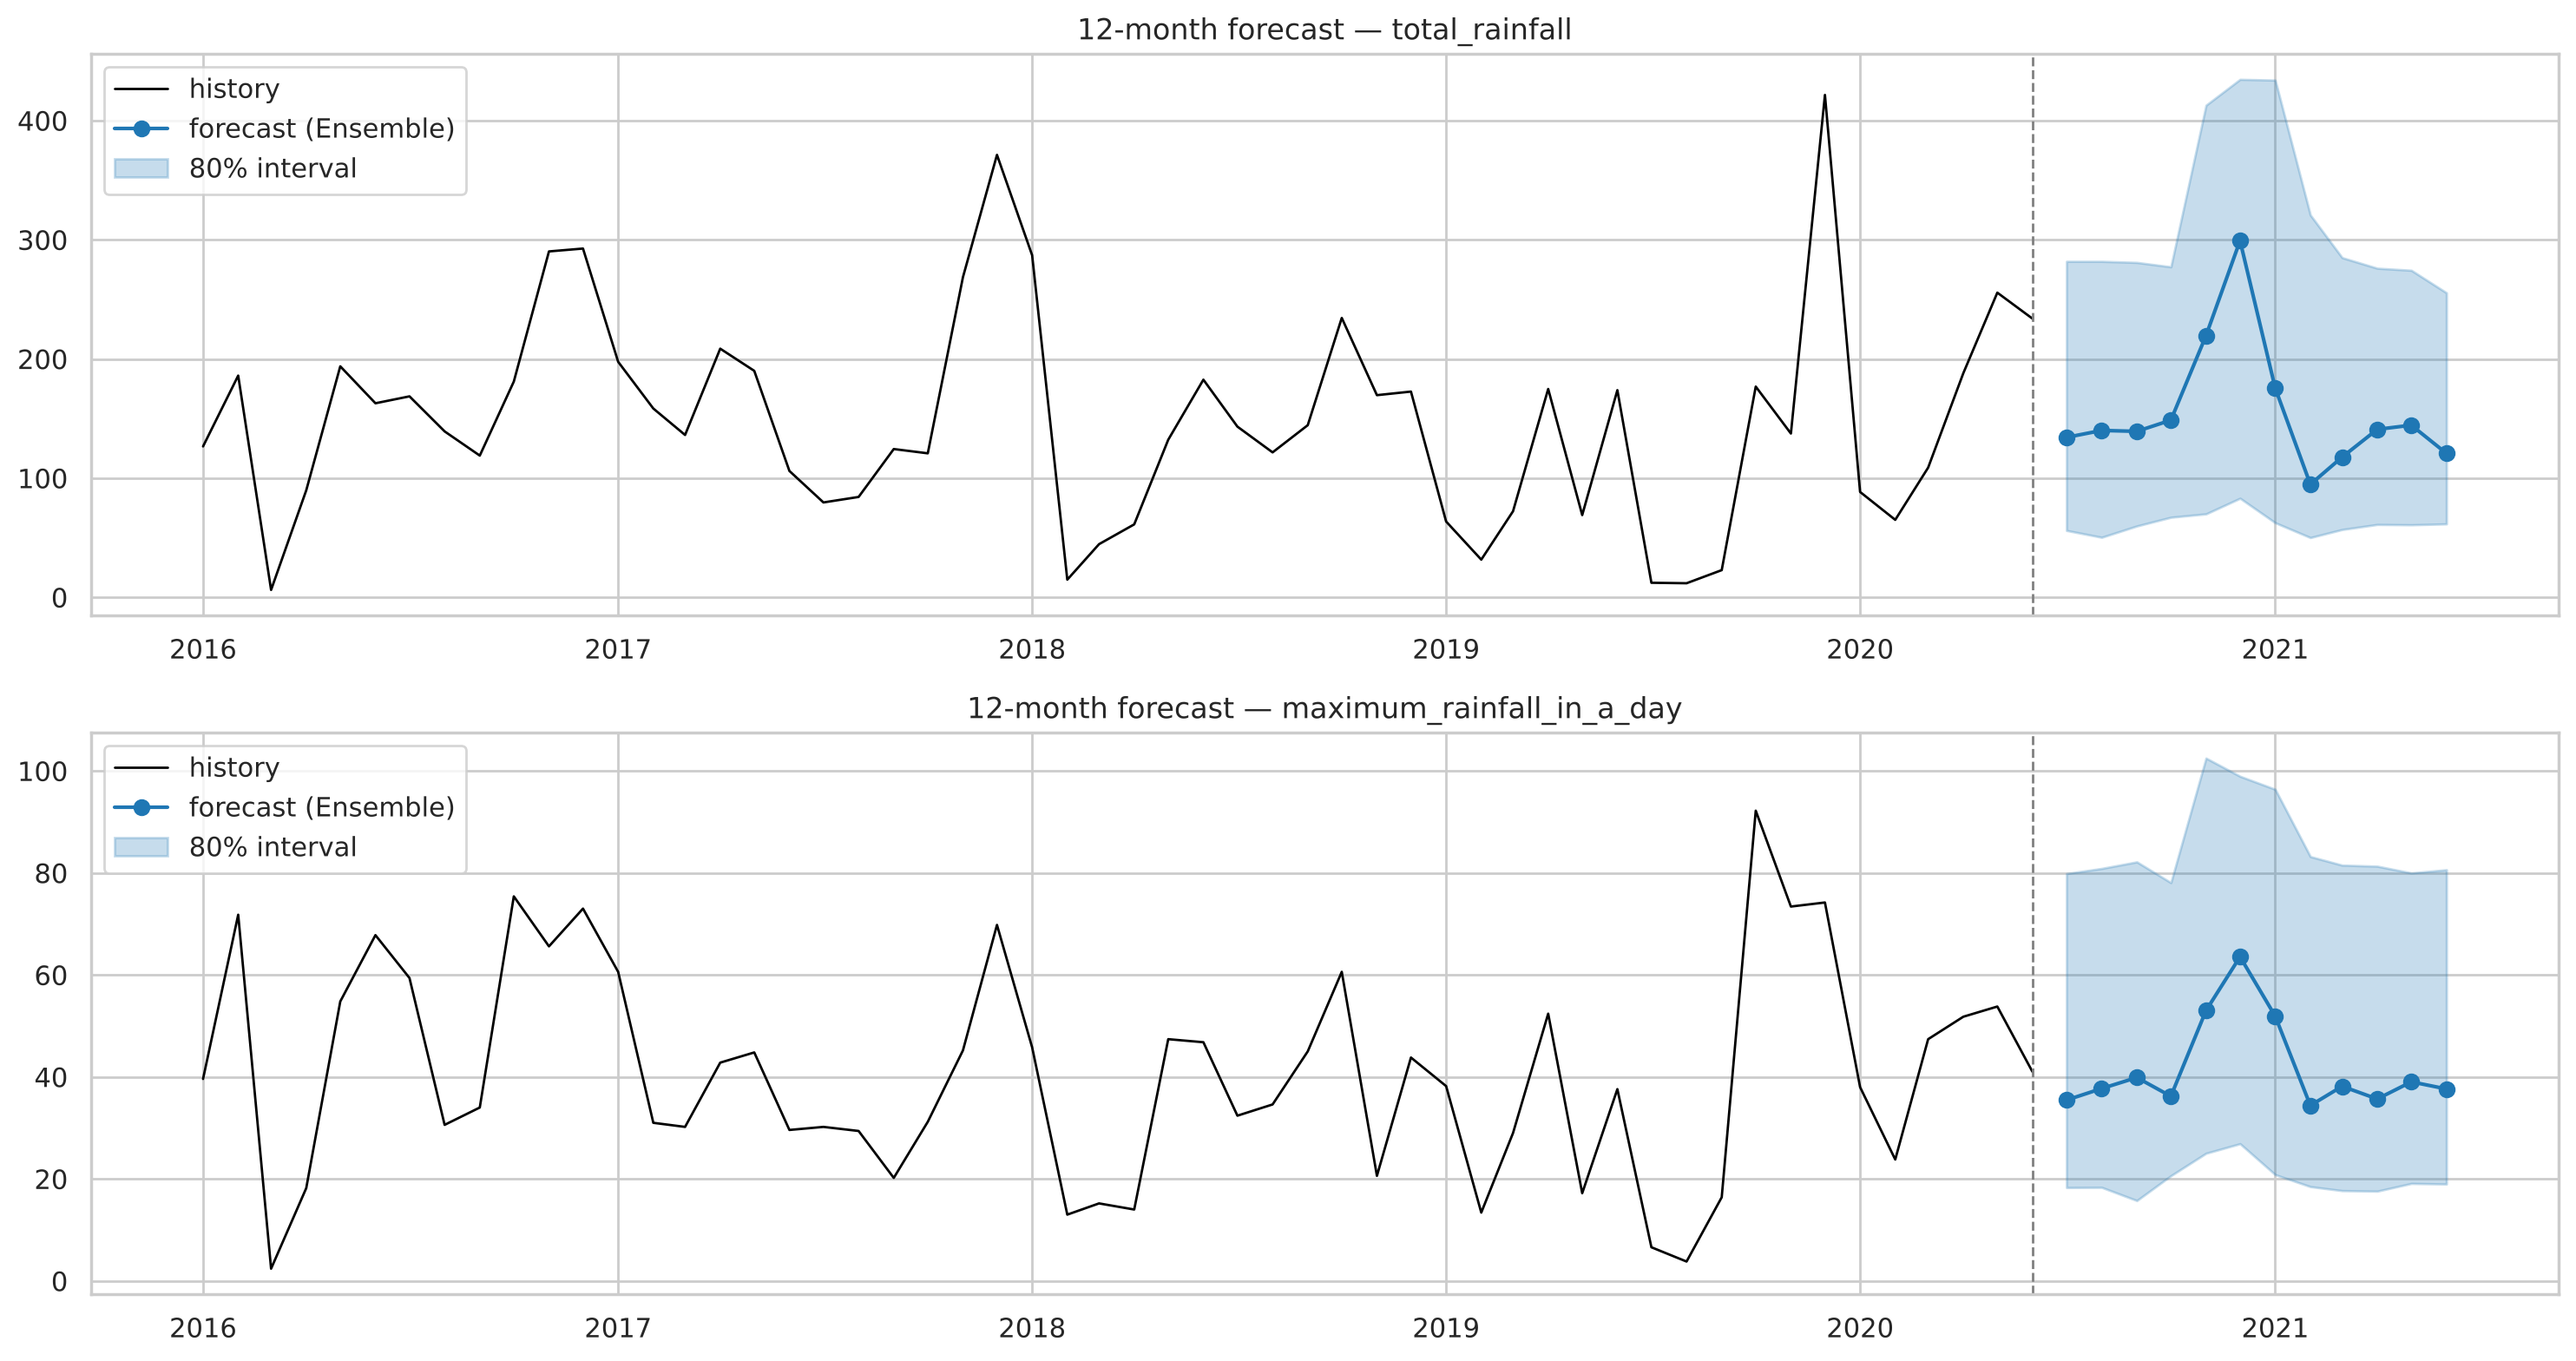

In [37]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
for ax, col in zip(axes, [TARGET_TOTAL, TARGET_MAX]):
    hist = df[col]['2016':]
    fc = final_forecasts[col]
    ax.plot(hist.index, hist, color='black', lw=1, label='history')
    ax.plot(fc.index, fc['forecast'], 'o-', color='tab:blue', label=f'forecast ({best_model[col]})')
    ax.fill_between(fc.index, fc['lower_80'], fc['upper_80'], alpha=0.25, color='tab:blue', label='80% interval')
    ax.axvline(df.index[-1], color='grey', ls='--', lw=1)
    ax.set_title(f'12-month forecast — {col}'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## 17. Save forecasts and model card

In [38]:
forecast_table.to_csv(f'{OUT_DIR}/forecast_2020-07_to_2021-06.csv')
lb_total.to_csv(f'{OUT_DIR}/leaderboard_total_rainfall.csv', index=False)
lb_max.to_csv(f'{OUT_DIR}/leaderboard_max_daily_rainfall.csv', index=False)
sig.to_csv(f'{OUT_DIR}/significance_vs_monthly_median.csv', index=False)
holdout_table.to_csv(f'{OUT_DIR}/holdout_results.csv', index=False)
with open(f'{OUT_DIR}/model_card.json', 'w') as fh:
    json.dump({'final_model': 'Ensemble', 'members': ENSEMBLE_MEMBERS, 'xgb_params': best_xgb_params,
               'horizon_months': H, 'train_period': [str(df.index.min().date()), str(df.index.max().date())],
               'backtest_origins': [str(o.date()) for o in BACKTEST_ORIGINS],
               'backtest_mae': {c: round(float(RESULTS[c]['Ensemble']['backtest']['MAE']), 2) for c in RESULTS}}, fh, indent=2)
print(sorted(os.listdir(OUT_DIR)))

['forecast_2020-07_to_2021-06.csv', 'holdout_results.csv', 'leaderboard_max_daily_rainfall.csv', 'leaderboard_total_rainfall.csv', 'maximum_rainfall_in_a_day_random_forest.joblib', 'maximum_rainfall_in_a_day_xgb_q10.joblib', 'maximum_rainfall_in_a_day_xgb_q90.joblib', 'model_card.json', 'significance_vs_monthly_median.csv', 'total_rainfall_xgb_q10.joblib', 'total_rainfall_xgb_q90.joblib']


## 18. Conclusions

### What the data says
- **Seasonality is the only strong signal.** The Northeast Monsoon (Nov–Jan) is clearly wetter than the rest of the year
  (December averages about 318 mm, February about 105 mm; tests in Section 4 reject equal months at p < 1e-9).
- **Almost no memory beyond the calendar.** Month-to-month autocorrelation is 0.20 for total rainfall and 0.14 for the
  highest daily rainfall. There is no significant long-term trend (about −4 mm/year, p = 0.52). Most of the
  variation is random, which sets a hard ceiling on forecast accuracy.

### What the models say (108 out-of-sample months, 12-month-ahead, MAE in mm)
| | Total rainfall | Highest daily rainfall |
|---|---|---|
| Seasonal naive (same month last year) | 86.2 | 28.8 |
| SARIMA (AIC-selected) | 68.9 | 21.8 |
| LSTM | 74.2 | 19.5 |
| Linear Regression / Random Forest / XGBoost | 64.8 / 64.6 / 64.6 | 19.4 / 18.9 / 19.0 |
| **Monthly median (baseline)** | **63.9** | **19.3** |
| **Ensemble (final model)** | **63.7** | **19.0** |

- The monthly median, the machine learning models and the ensemble beat "same month last year" by 25–34%, but **none of the machine learning
  models is significantly better than simply using the historical median of each calendar month** (Wilcoxon
  p between 0.54 and 0.92). The classical time series models (AR, ARIMA, SARIMA, Holt-Winters) are worse, significantly so for most of them
  (SARIMA on total rainfall is the exception, p = 0.07).
- The ensemble was chosen by design because no single model is reliably best. It is statistically indistinguishable from the
  monthly median, so **the monthly median is an equally valid, simpler choice**. On the holdout year the median was
  actually slightly better (total 84.9 vs 86.8 mm, highest daily 17.2 vs 20.0 mm); one year of 12 points is noisy, so this
  neither confirms nor overturns the backtest.
- The LSTM did not help, as expected with about 400 training windows.

### Forecast for July 2020 – June 2021
- The wettest months are expected to be November–January (December about 299 mm total, with a highest single day of about
  64 mm); the driest is February (about 95 mm).
- **The point forecasts are typical-month values (median-like), not expected values.** Rainfall is right-skewed, so
  the 12 monthly forecasts add up to about 1,875 mm, below the long-run annual mean of 2,118 mm. If the business needs an
  expected annual total, use monthly means, not these medians.
- **Uncertainty is large.** The 80% intervals are wide (about 255 mm for total rainfall and 70 mm for the highest daily
  rainfall) and contain the actual value 85% and 80% of the time in the backtest. Any single month can easily be
  twice the forecast or half of it.

### Limitations and next steps
- One station, monthly data, no weather drivers. The largest known driver of year-to-year variation (El Niño / La Niña,
  ENSO index) is not in this dataset; adding it is the most promising way to beat the monthly median.
- Daily data would allow modelling the number of heavy-rain days directly, and extreme-value methods for the highest daily rainfall.
- The forecasts cover only the next 12 months from the end of the data (June 2020); features need data at least 12 months old.
- The 2020 data stops in June; the actual July 2020 – June 2021 values (published by NEA on data.gov.sg) can be used to score this forecast.